# Import Dataset and Data Exploration

In [127]:
import pandas as pd
import numpy as numpy

df = pd.read_csv("MI7_GROUNDWATERSCHEME_ASSAM.csv")

In [128]:
print(df.shape)
df.head()

(57303, 64)


,serial_no,state_name,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,dugwell_type,...,ipc_total,ipu_kharif_season,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,under_utilisation_reason,drinking_water_purpose,captured_in_previous_census
0,1,ASSAM,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,NaN,...,5.0,4.0,1.0,0.00,0.00,5.00,NaN,NaN,No,No
1,2,ASSAM,Kokrajhar,Kokrajhar,Bhadiaguri,26.355332,90.233585,12,Tube well,NaN,...,1.0,0.4,0.2,0.09,0.08,0.77,NaN,NaN,No,No
2,3,ASSAM,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,NaN,...,4.0,4.0,0.0,0.00,0.00,4.00,NaN,NaN,No,Yes
3,4,ASSAM,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.210017,90.160672,4,Tube well,NaN,...,3.5,2.0,1.5,0.00,0.00,3.50,No,NaN,No,No
4,5,ASSAM,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.208178,90.161543,7,Tube well,NaN,...,4.5,2.5,2.0,0.00,0.00,4.50,No,NaN,No,No


In [129]:
df.drop(columns=["serial_no", "state_name"], inplace=True) #serial_no is unique number for each row and state_name is ASSAM across all rows

# Fixing Data Types

In [130]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57303 entries, 0 to 57302
Data columns (total 62 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   district_name                       57303 non-null  object 
 1   block_tehsil_name                   57303 non-null  object 
 2   village_name                        57303 non-null  object 
 3   latitude                            57303 non-null  float64
 4   longitude                           57303 non-null  float64
 5   s_no_of_scheme                      57303 non-null  int64  
 6   scheme_type                         57303 non-null  object 
 7   dugwell_type                        809 non-null    object 
 8   tubewell_type                       56494 non-null  object 
 9   ownership                           57303 non-null  object 
 10  khasra_number                       24023 non-null  object 
 11  location_particulars                51320

In [131]:
cols = [col for col in df.columns]

for col in cols:
    print(f"\n{'=' * 50}")
    print("Column:", col)
    print("Data type:", df[col].dtype)
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isna().sum())
    print(df[col].value_counts(dropna=False).head(15))


Column: district_name
Data type: object
Unique values: 34
Missing values: 0
district_name
Dhubri        14841
Barpeta       10315
Marigaon       5020
Bongaigaon     2922
Kamrup         2285
Goalpara       2273
Nagaon         2160
Darrang        2104
Golaghat       1272
Lakhimpur      1201
Kokrajhar      1149
Cachar         1067
Sonitpur       1064
Tinsukia        962
Hojai           927
Name: count, dtype: int64

Column: block_tehsil_name
Data type: object
Unique values: 227
Missing values: 0
block_tehsil_name
Mandia              3429
Debitola            2475
Gauripur            2291
Mahamaya            2114
Pakabetbari         1791
Laharighat          1780
Rupshi              1473
Ruposhi             1292
Agomani             1273
Chenga              1194
Mayang              1159
Birshing-Jarua      1118
Dalgaon-Sialmari    1098
Barpeta              988
Nayeralga            920
Name: count, dtype: int64

Column: village_name
Data type: object
Unique values: 8393
Missing values: 0
vill

In [132]:
"""
vilage name may need to be dropped 
s no of schemes may need to be dropped
scheme type most data is tube well 
Khashar number needs to be converted to int
location particular may need to be dropped
social status needs missing value analysis
gender needs missing value analysis
scheme diamaeter has missing values
bore depth has mostly missng values find MCAR MAR MNAR
machinery_cost, maintenance_cost are calculated after finding construction_cost so they need to be dropped
finance source 1 nad 2 need to be merged
construction_subsidy, machinery_subsidy need to be analysed and may need to be dropped 
scheme_status may not be useful 
not_in_use_years need to analyse MCAR MAR
status_reason_temporarily may need to be dropped
status_reason_permanently may need to be dropped
water_distribution_method, lifting_device_type, energy_source, horse_power_of_lifting_device handle missing
pump_operating_days_kharif_season, pump_operating_days_rabi_season, pump_operating_days_perennial_crop, pump_operating_days_other_season handle missing nad check data type
avg_pumping_per_day_kharif_season, avg_pumping_per_day_rabi_season, avg_pumping_per_day_perennial_crop, avg_pumping_per_day_other_season handle missing
located_in_command_area may be useless 
name_of_mmi_project, scheme_in_command_area_reason may need to be dropped
only_recharge_ground_water analyze ma need to remove
ipu_perennial_crop, ipu_other_season, under_utilised_selection handle missing
under_utilisation_reason may need to be dropped 
captured_in_previous_census, handle missing
"""

'\nvilage name may need to be dropped \ns no of schemes may need to be dropped\nscheme type most data is tube well \nKhashar number needs to be converted to int\nlocation particular may need to be dropped\nsocial status needs missing value analysis\ngender needs missing value analysis\nscheme diamaeter has missing values\nbore depth has mostly missng values find MCAR MAR MNAR\nmachinery_cost, maintenance_cost are calculated after finding construction_cost so they need to be dropped\nfinance source 1 nad 2 need to be merged\nconstruction_subsidy, machinery_subsidy need to be analysed and may need to be dropped \nscheme_status may not be useful \nnot_in_use_years need to analyse MCAR MAR\nstatus_reason_temporarily may need to be dropped\nstatus_reason_permanently may need to be dropped\nwater_distribution_method, lifting_device_type, energy_source, horse_power_of_lifting_device handle missing\npump_operating_days_kharif_season, pump_operating_days_rabi_season, pump_operating_days_perenni

In [133]:
df['khasra_number'] = (
    pd.to_numeric(df['khasra_number'], errors='coerce')
    .astype('Int64')
)

# converted khasra_number to int
df['khasra_number'].isna().sum()

np.int64(49735)

# Missing Value Analysis and Handling

In [134]:
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [135]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': (missing / len(df)) * 100
})

missing_df = missing_df.sort_values(
    by='Missing Percentage', ascending=False
)

missing_df[missing_df['Missing Values'] > 0]

,Missing Values,Missing Percentage
scheme_in_command_area_reason,57157,99.745214
name_of_mmi_project,57142,99.719037
status_reason_permanently,56536,98.661501
dugwell_type,56494,98.588207
status_reason_temporarily,51961,90.677626
not_in_use_years,51194,89.339127
khasra_number,49735,86.793013
under_utilisation_reason,48757,85.086296
finance_source2,23688,41.338150
finance_source1,15969,27.867651


In [136]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300

In [137]:
# the Colums with more than 20% missing value smay need to be dropped and more than 90% will be dropped

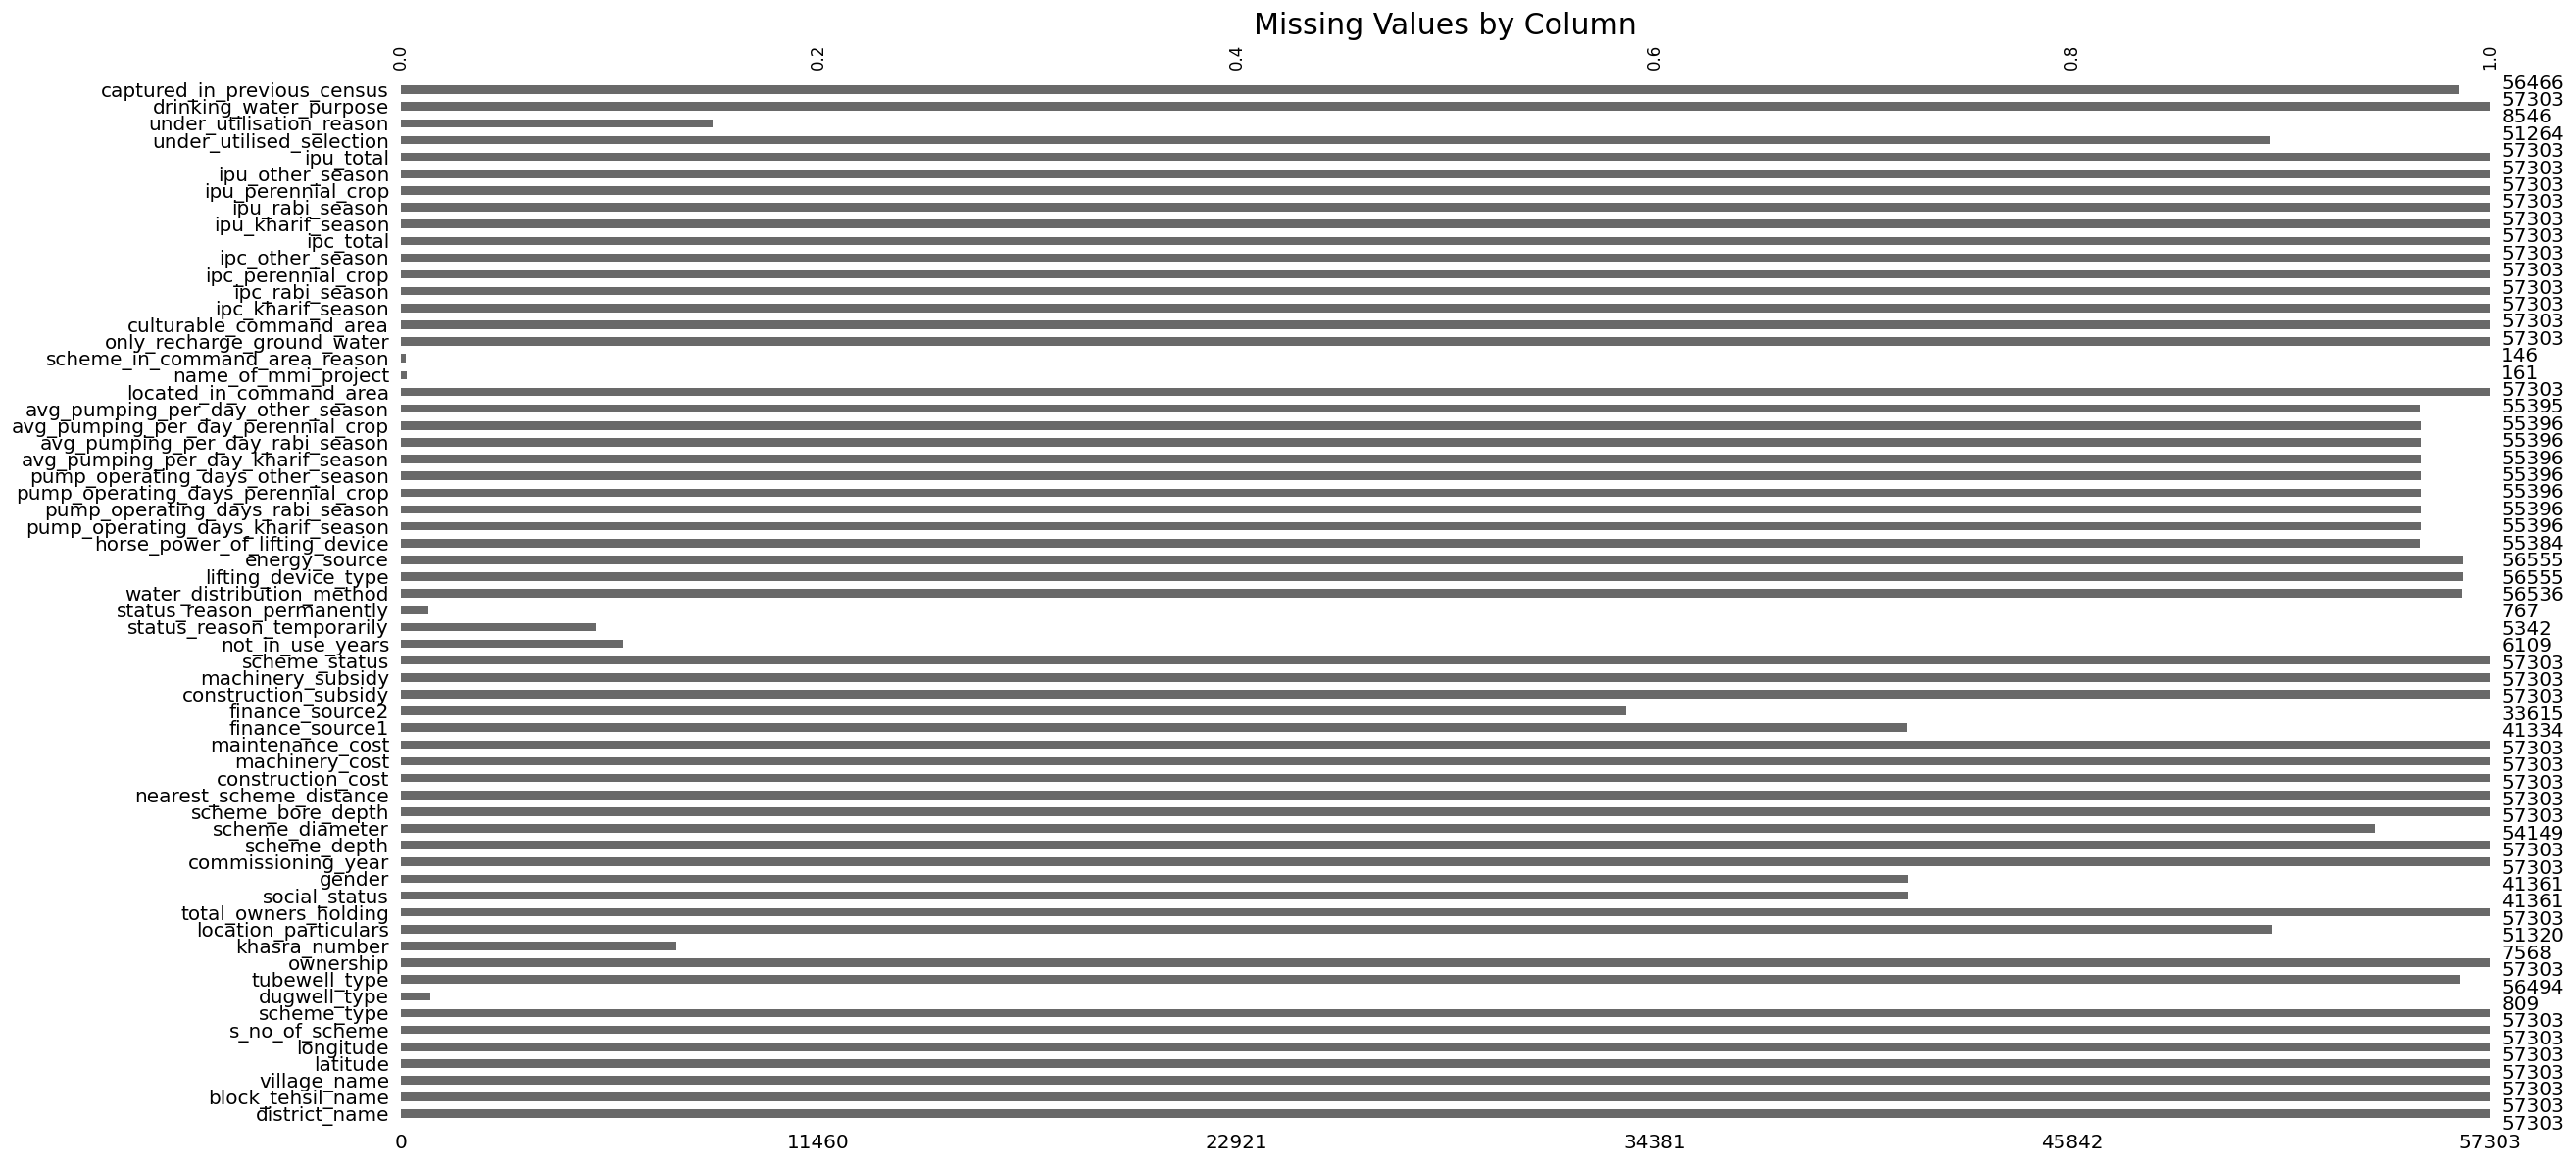

In [138]:
msno.bar(df, figsize=(22, 10), fontsize=12)
plt.title('Missing Values by Column', fontsize=18)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

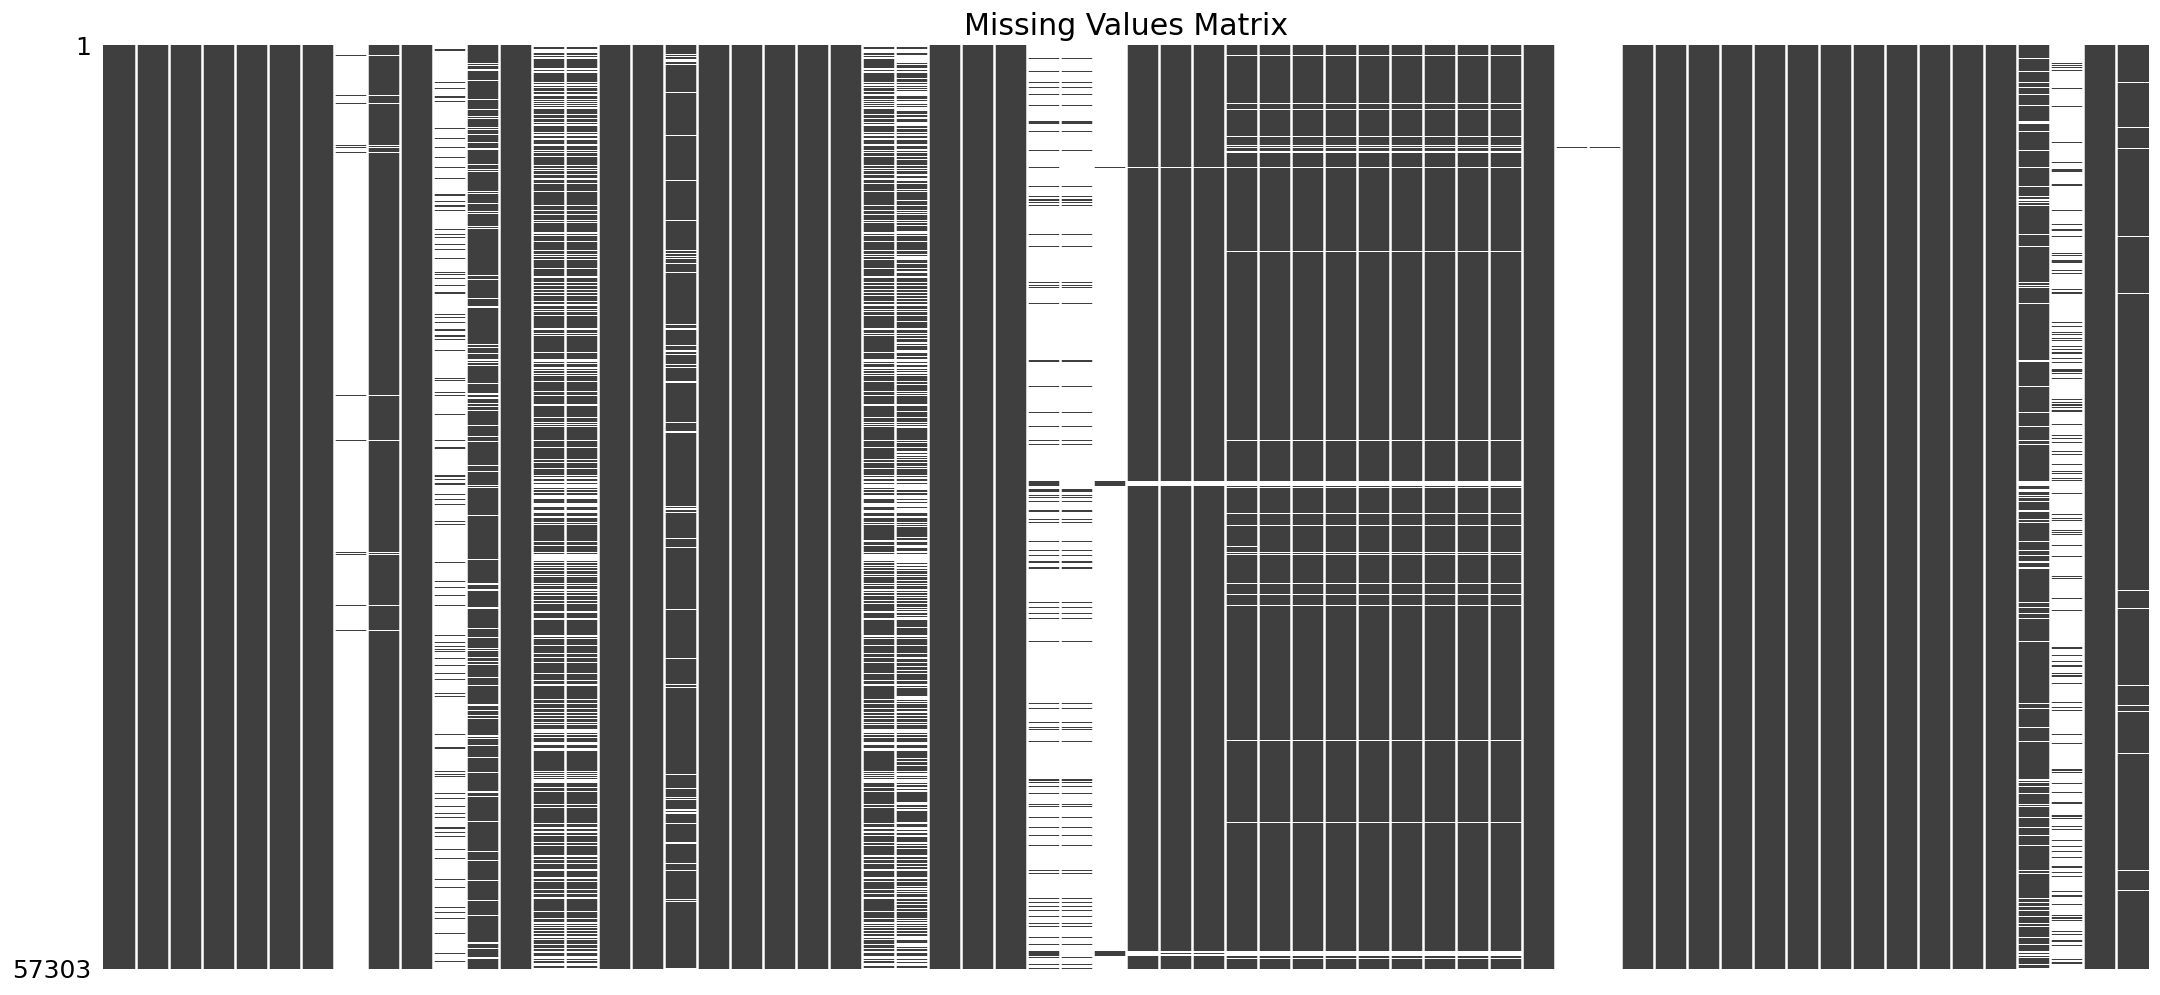

In [139]:
msno.matrix(df, figsize=(22, 10), sparkline=False, fontsize=12)
plt.title('Missing Values Matrix', fontsize=18)
plt.show()

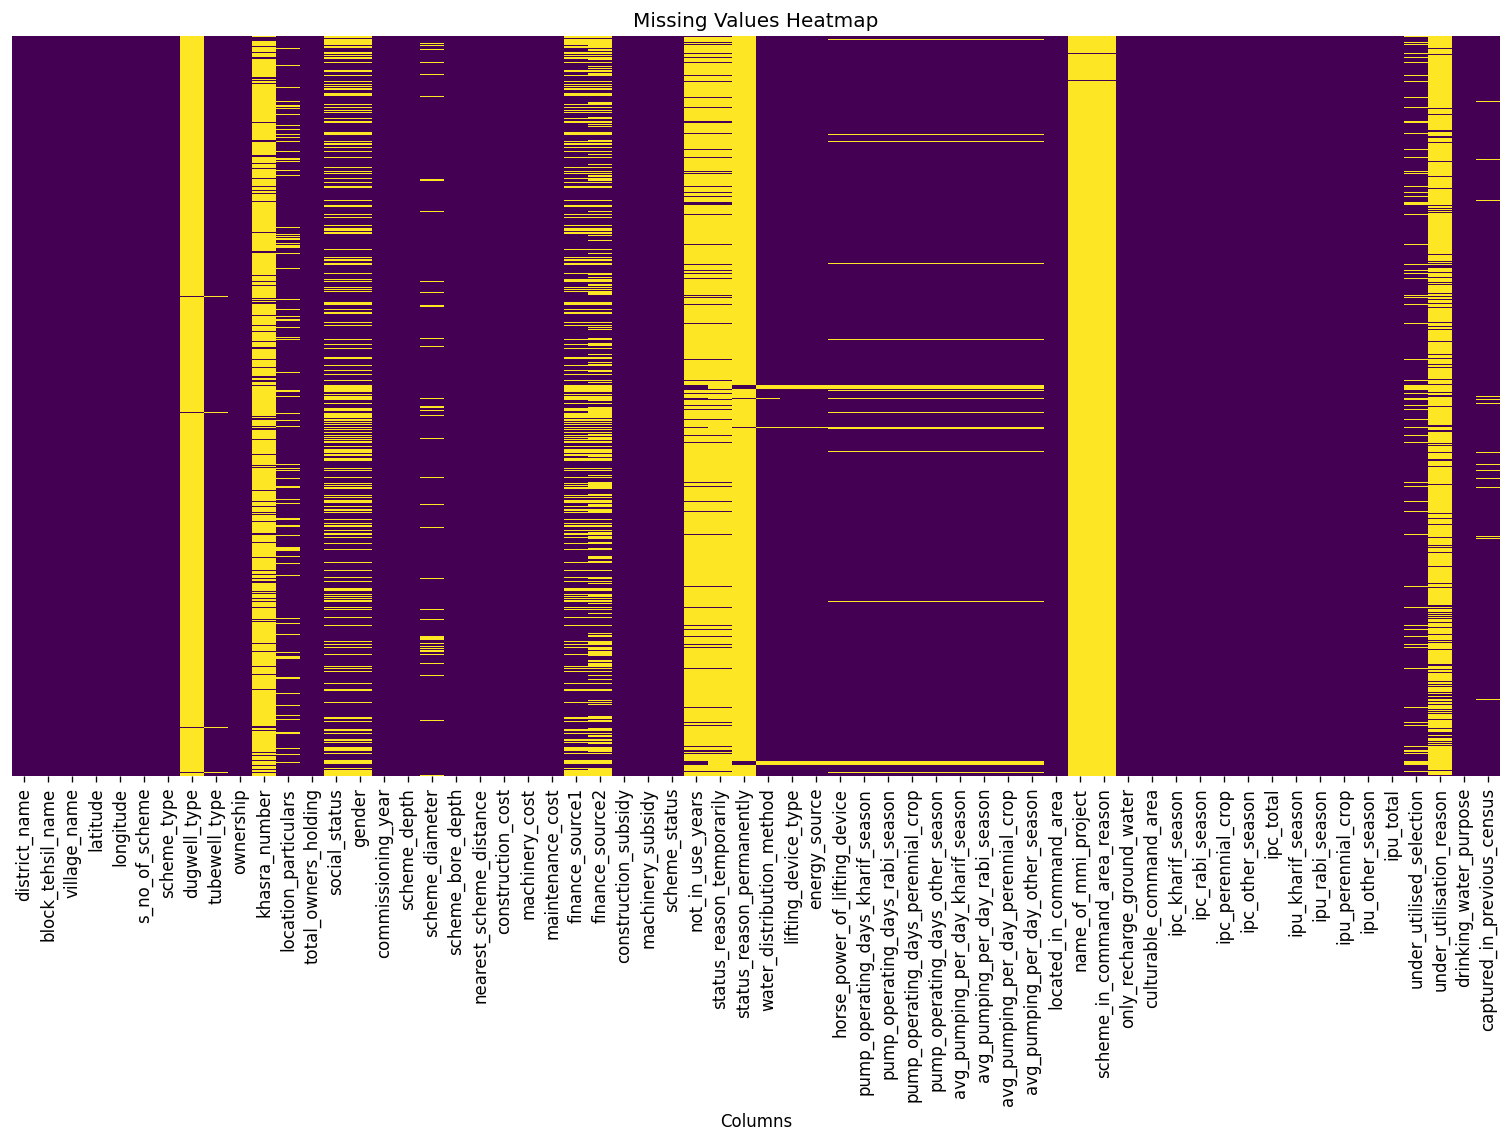

In [140]:
plt.figure(figsize=(16, 8))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap')
plt.xlabel('Columns')
plt.show()

In [141]:
# Dougwell type and Tube well type have relation

# not_in_use_years	status_reason_temporarily, status_reason_permanently, water_distribution_method, lifting_device_type, energy_source	
# horse_power_of_lifting_device, pump_operating_days_kharif_season, pump_operating_days_rabi_season, pump_operating_days_perennial_crop
# pump_operating_days_other_season, avg_pumping_per_day_kharif_season, avg_pumping_per_day_rabi_season, avg_pumping_per_day_perennial_crop, 
# avg_pumping_per_day_other_season are related

# there is a relation between under_utilised_selection	under_utilisation_reason

# there is a realtion between not_in_use_years	status_reason_temporarily


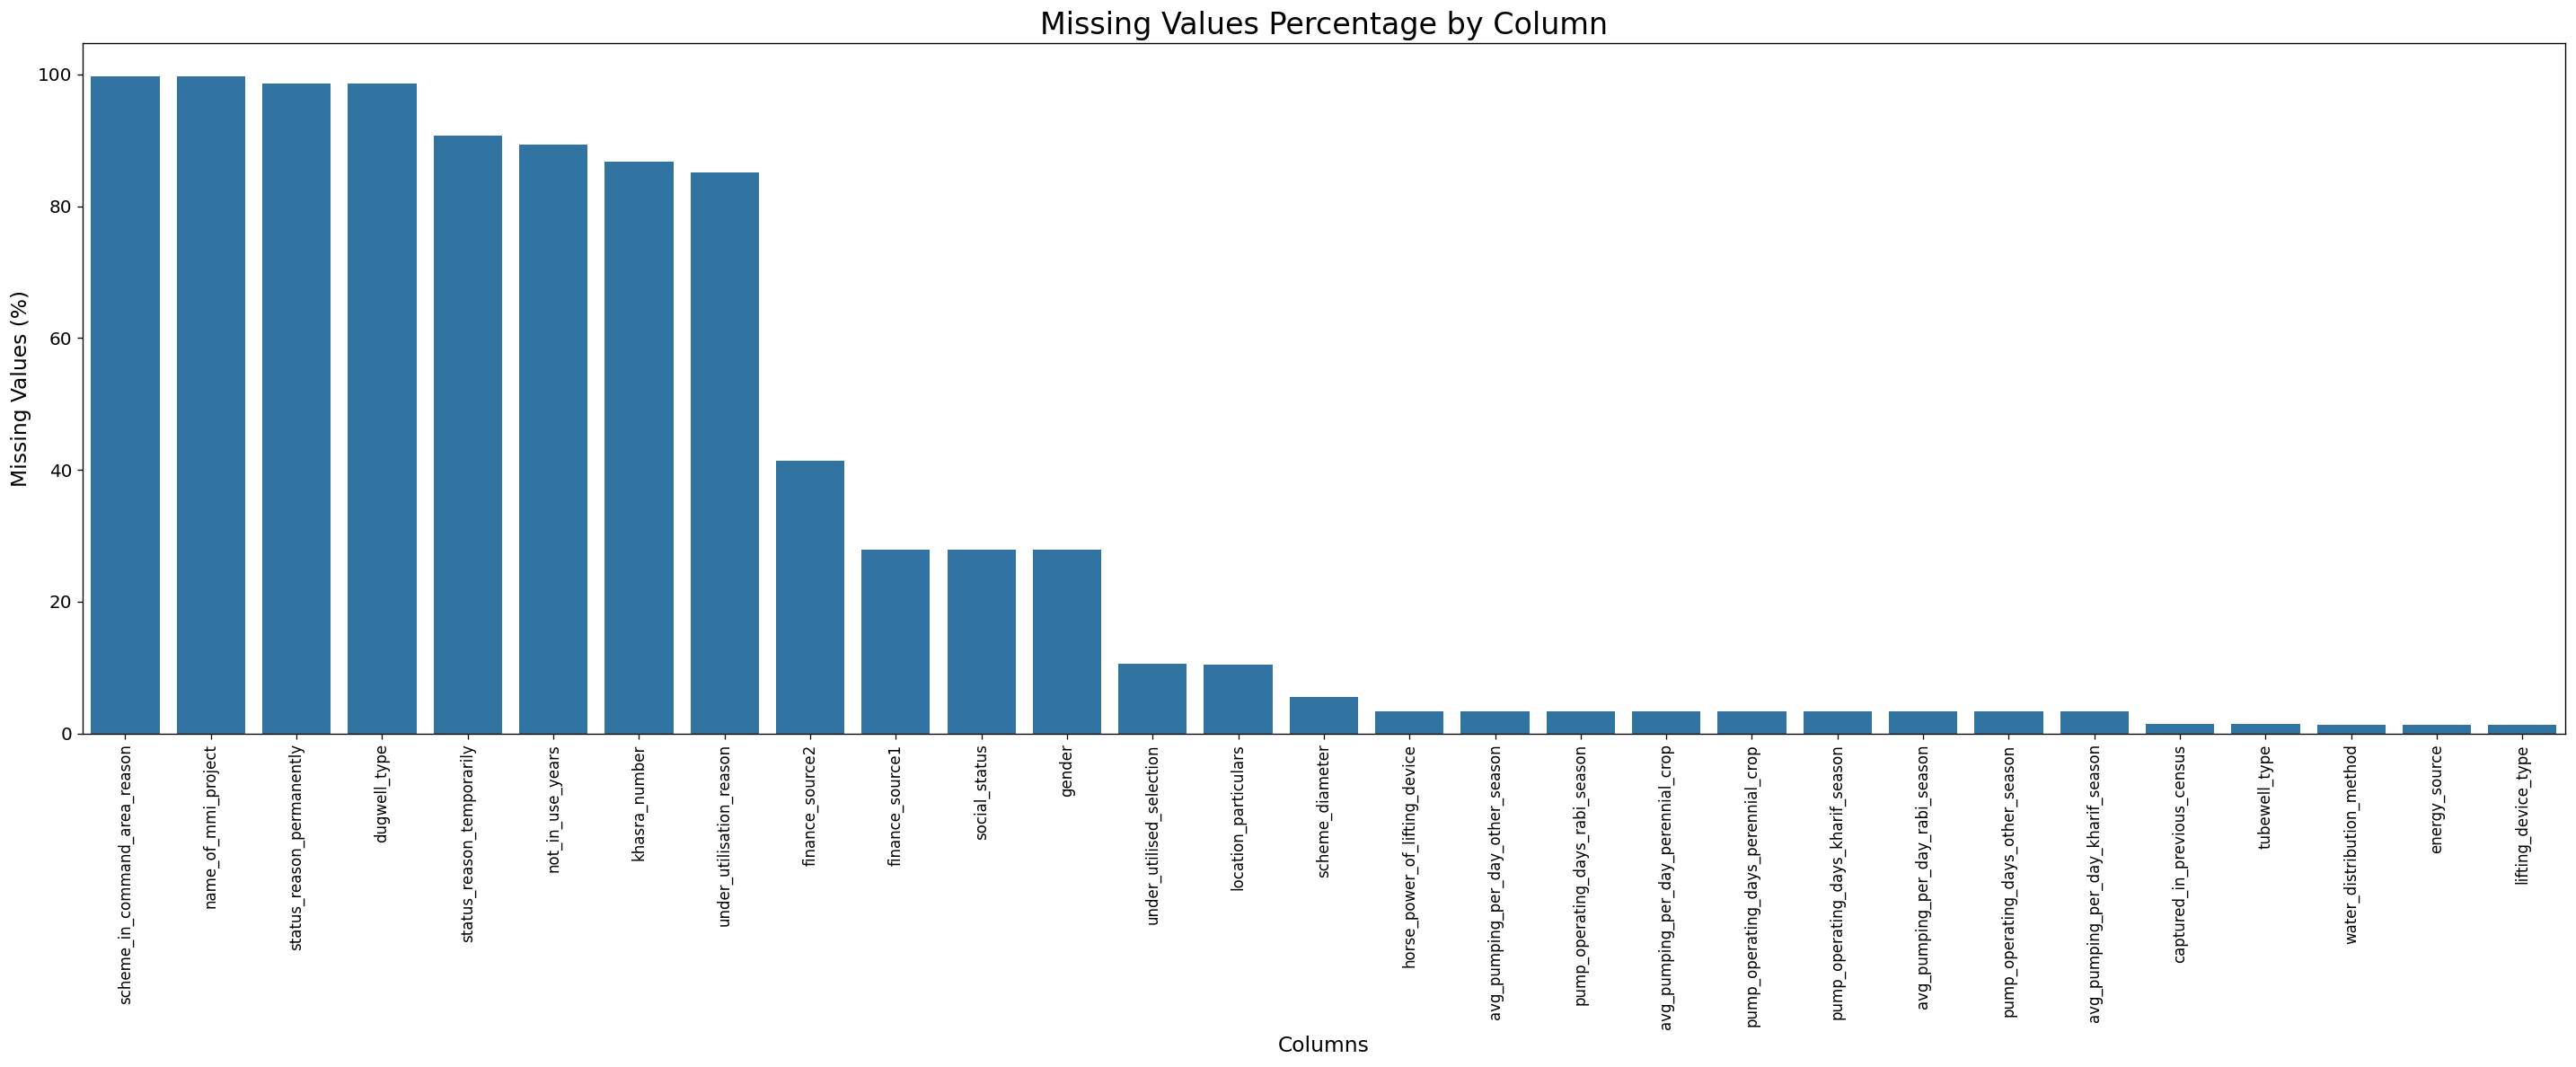

In [142]:
missing_pct = (df.isnull().mean() * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

plt.figure(figsize=(24, 10))

sns.barplot(
    x=missing_pct.index,
    y=missing_pct.values
)

plt.title('Missing Values Percentage by Column', fontsize=20)
plt.xlabel('Columns', fontsize=14)
plt.ylabel('Missing Values (%)', fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

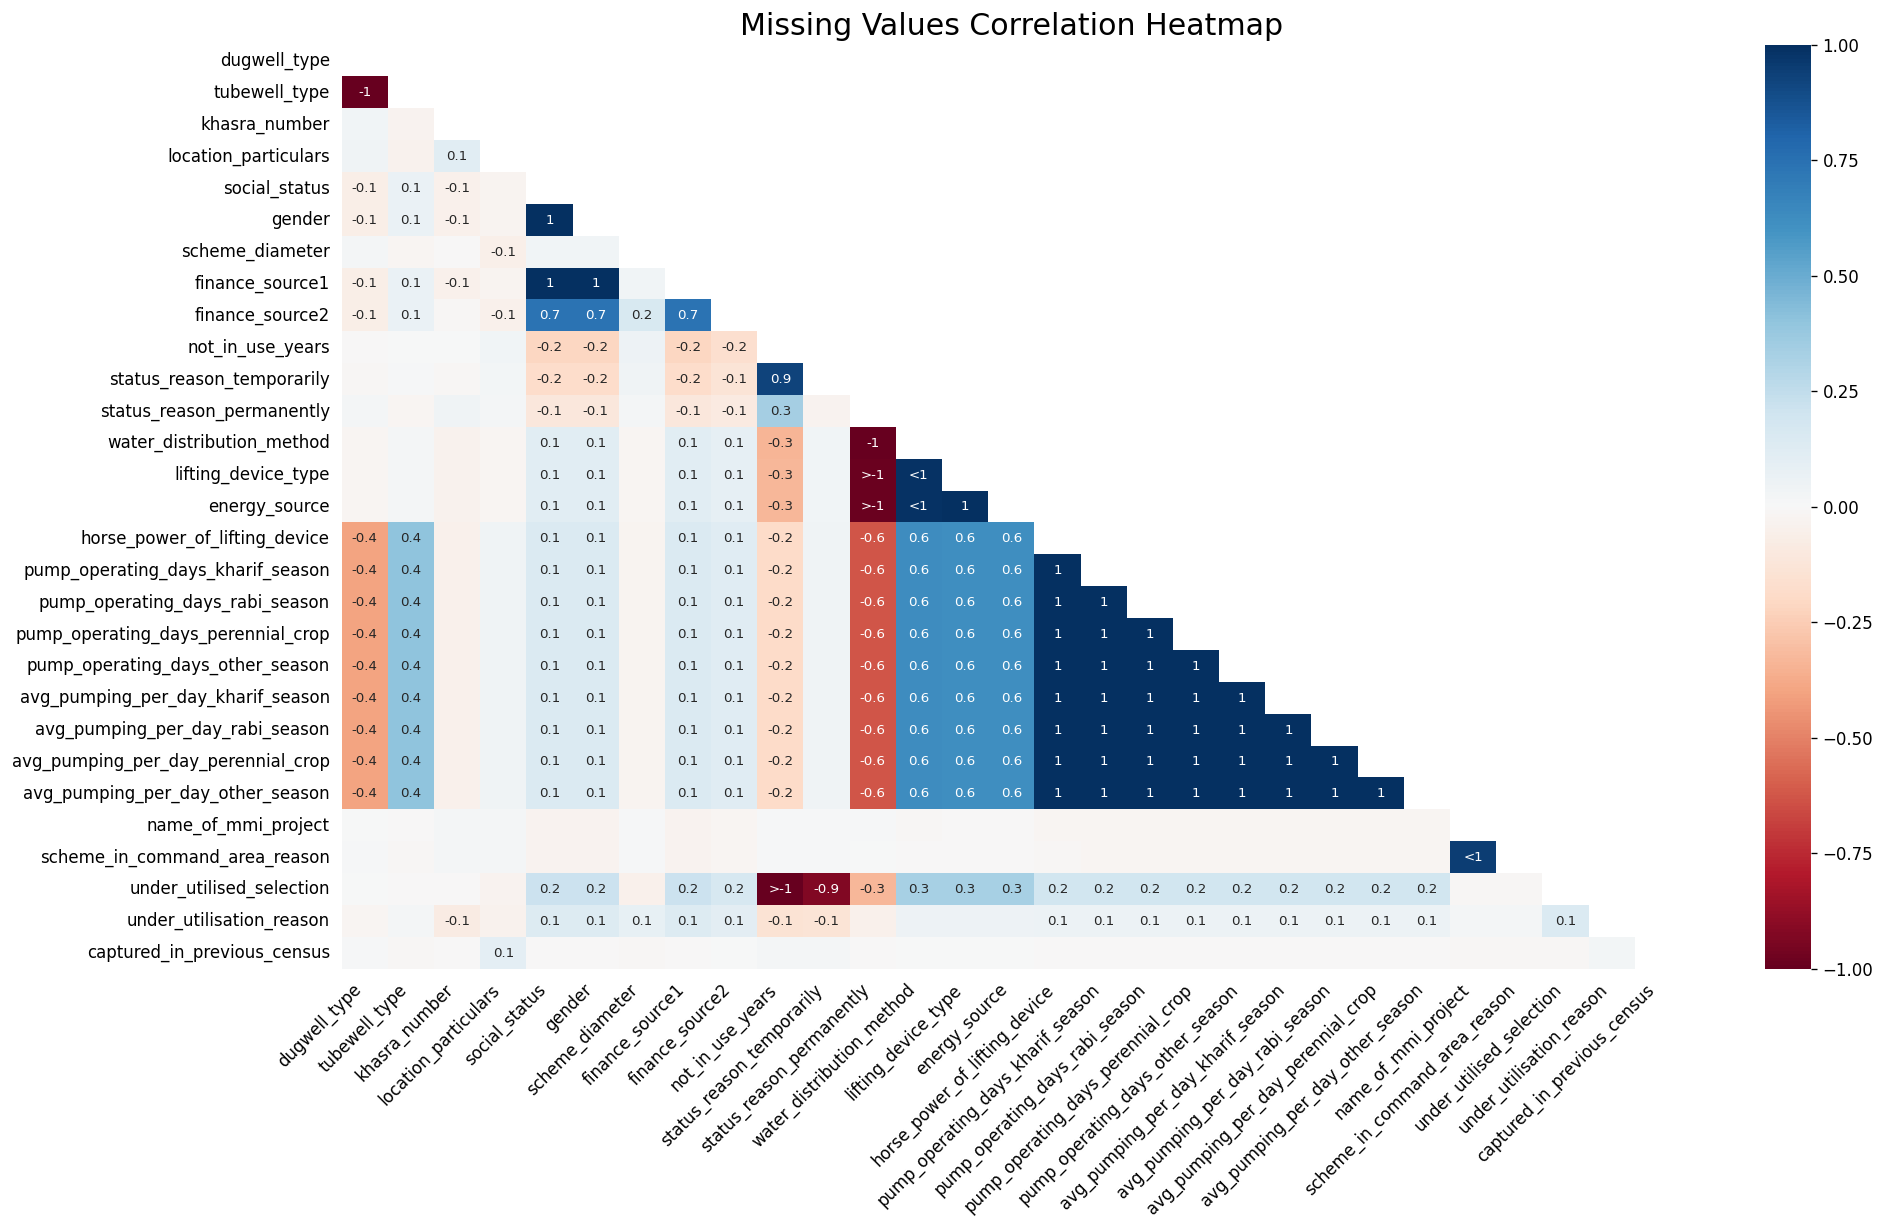

In [143]:
msno.heatmap(df, figsize=(18, 10), fontsize=10)
plt.title('Missing Values Correlation Heatmap', fontsize=18)
plt.show()

In [144]:
# there apears to be a relation between finance sorce and social status and gender
# status reason and not un use years have relation 

<Figure size 4500x2100 with 0 Axes>

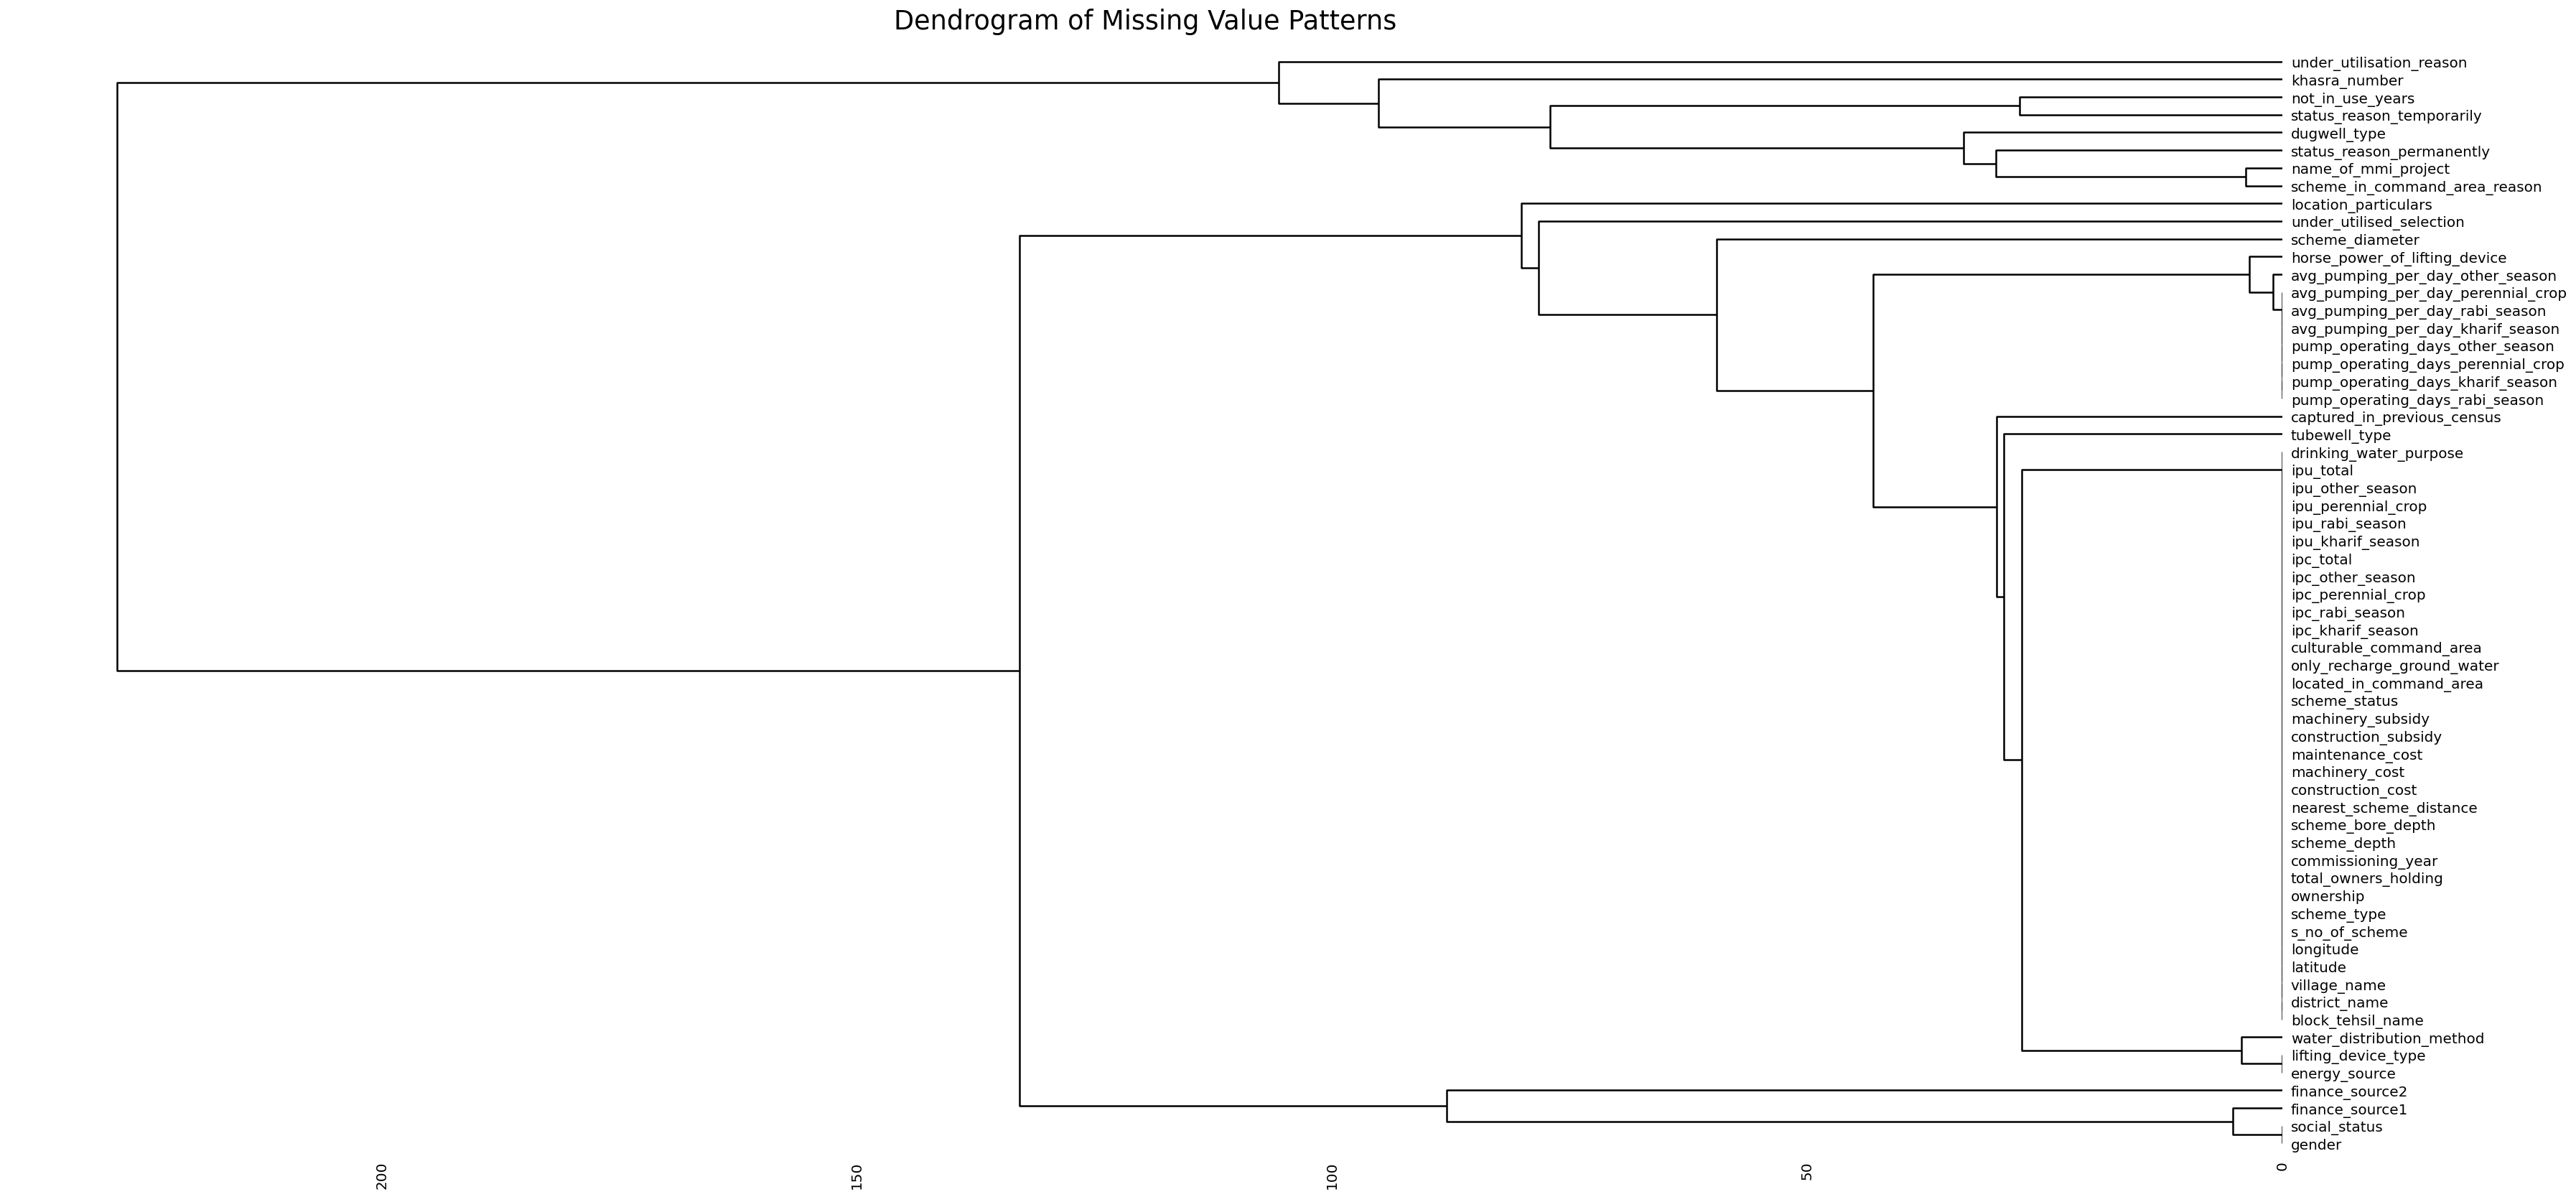

In [145]:
plt.figure(figsize=(30, 14), dpi=150)

msno.dendrogram(
    df,
    figsize=(30, 14),
    fontsize=14
)

plt.title('Dendrogram of Missing Value Patterns', fontsize=22, pad=20)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

In [146]:
# Captured in previous sencus and well type are related
# Location and underutilization are related

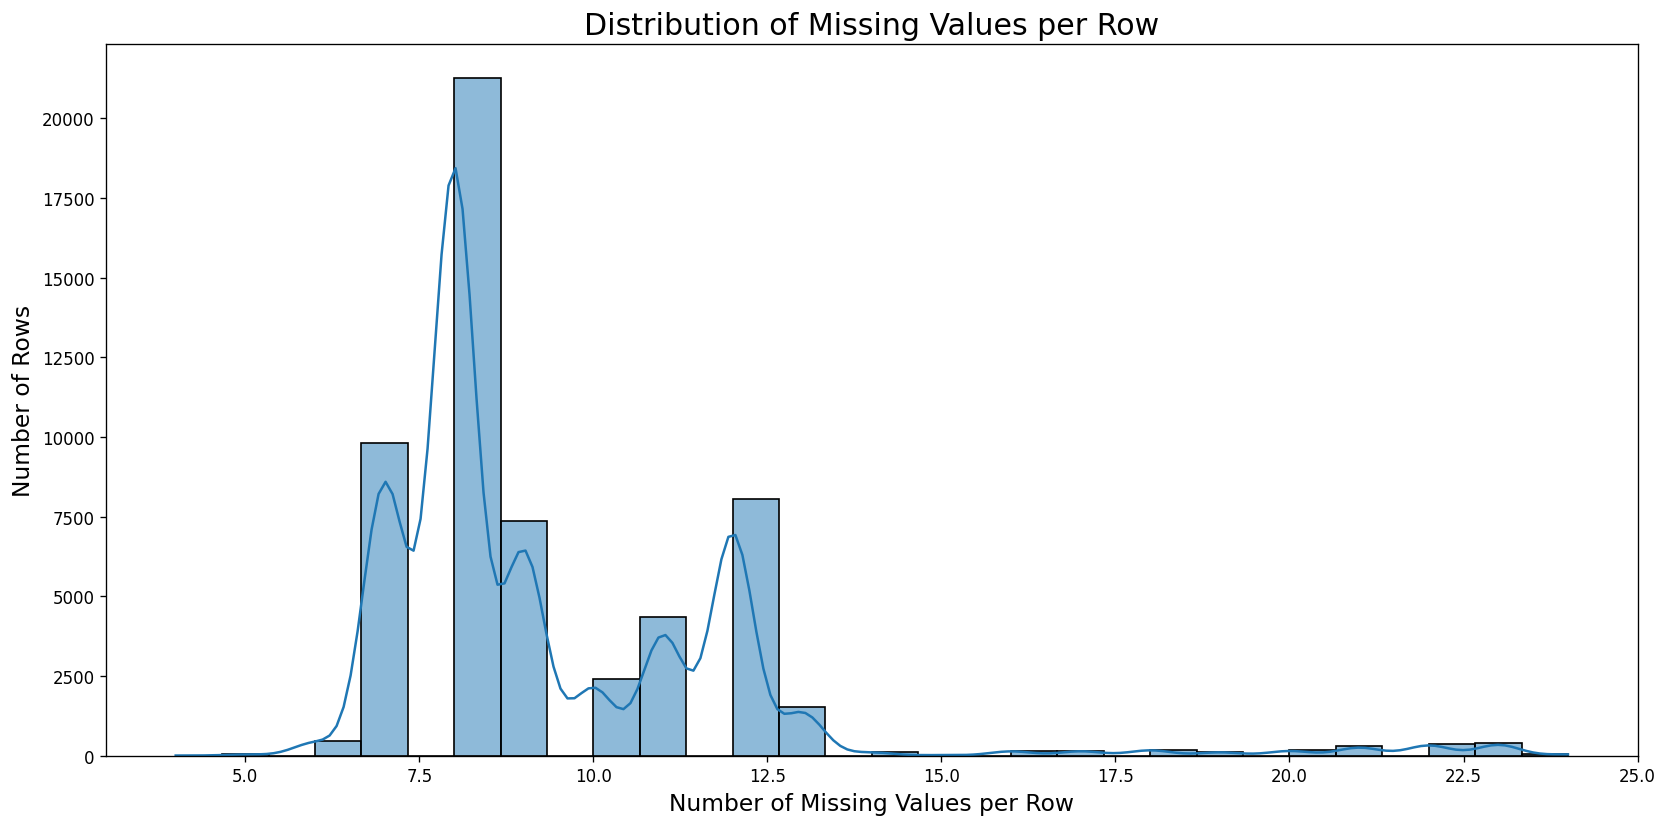

In [147]:
missing_per_row = df.isnull().sum(axis=1)

plt.figure(figsize=(14, 7))

sns.histplot(
    missing_per_row,
    bins=30,
    kde=True
)

plt.title('Distribution of Missing Values per Row', fontsize=18)
plt.xlabel('Number of Missing Values per Row', fontsize=14)
plt.ylabel('Number of Rows', fontsize=14)
plt.tight_layout()
plt.show()

In [148]:
missing_per_row = df.isnull().sum(axis=1)

print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Average missing values per row:", round(missing_per_row.mean(), 2))
print("Median missing values per row:", missing_per_row.median())
print("Maximum missing values in a row:", missing_per_row.max())

print("Rows with no missing values:",
      (missing_per_row == 0).sum())

print("Rows with more than 50% missing:",
      (missing_per_row > len(df.columns) * 0.5).sum())

print("Rows with more than 80% missing:",
      (missing_per_row > len(df.columns) * 0.8).sum())

Total records: 57303
Total columns: 62
Average missing values per row: 9.37
Median missing values per row: 8.0
Maximum missing values in a row: 24
Rows with no missing values: 0
Rows with more than 50% missing: 0
Rows with more than 80% missing: 0


In [149]:
row_missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(axis=1),
    'Missing_Percentage': df.isnull().mean(axis=1) * 100
})

row_missing_summary = row_missing_summary.sort_values(
    'Missing_Percentage',
    ascending=False
)

row_missing_summary.head(10)

,Missing_Count,Missing_Percentage
56237,24,38.709677
40267,24,38.709677
48500,24,38.709677
27163,24,38.709677
27012,24,38.709677
27034,24,38.709677
257,24,38.709677
27272,24,38.709677
56212,24,38.709677
34235,24,38.709677


In [150]:
from IPython.display import display

with pd.option_context(
    'display.max_columns', None,
    'display.max_rows', None,
    'display.max_colwidth', None,
    'display.width', None
):
    display(df.loc[row_missing_summary.head(10).index])

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,dugwell_type,tubewell_type,ownership,khasra_number,location_particulars,total_owners_holding,social_status,gender,commissioning_year,scheme_depth,scheme_diameter,scheme_bore_depth,nearest_scheme_distance,construction_cost,machinery_cost,maintenance_cost,finance_source1,finance_source2,construction_subsidy,machinery_subsidy,scheme_status,not_in_use_years,status_reason_temporarily,status_reason_permanently,water_distribution_method,lifting_device_type,energy_source,horse_power_of_lifting_device,pump_operating_days_kharif_season,pump_operating_days_rabi_season,pump_operating_days_perennial_crop,pump_operating_days_other_season,avg_pumping_per_day_kharif_season,avg_pumping_per_day_rabi_season,avg_pumping_per_day_perennial_crop,avg_pumping_per_day_other_season,located_in_command_area,name_of_mmi_project,scheme_in_command_area_reason,only_recharge_ground_water,culturable_command_area,ipc_kharif_season,ipc_rabi_season,ipc_perennial_crop,ipc_other_season,ipc_total,ipu_kharif_season,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,under_utilisation_reason,drinking_water_purpose,captured_in_previous_census
56237,Darrang,Bechimari,Sarichabari,26.571509,92.168028,4,Tube well,NaN,Shallow Tube well,Govt. Owned,<NA>,NaN,0.0,NaN,NaN,During 2019-2020,30.0,0.15,0.0,200.0,427200.0,427200.0,10000.0,NaN,NaN,427200.0,427200.0,Permanently Not in use,5.0,NaN,Destroyed beyond repair,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,2.0,1.0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,No
40267,Darrang,Dalgaon-Sialmari,Baruajhar 1/2,26.611632,92.137456,7,Tube well,NaN,Medium Tube well,Govt. Owned,<NA>,NaN,0.0,NaN,NaN,During 2019-2020,43.3,250.00,0.0,200.0,427200.0,427200.0,427200.0,NaN,NaN,427200.0,427200.0,Permanently Not in use,3.0,NaN,Destroyed beyond repair,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,2.0,1.0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,No
48500,Karimganj,Badarpur,Harinadik,24.811412,92.522090,7,Tube well,NaN,Shallow Tube well,Govt. Owned,<NA>,n a,0.0,NaN,NaN,During 2020-2021,25.0,NaN,0.0,300.0,40000.0,25000.0,30000.0,NaN,NaN,30000.0,25000.0,Permanently Not in use,3.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,No,6.0,4.0,2.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,No
27163,Darrang,Dalgaon-Sialmari,No.1 Sialmarikhuti,26.537415,92.202207,6,Tube well,NaN,Deep Tube well,Govt. Owned,<NA>,NaN,0.0,NaN,NaN,During 2020-2021,90.0,250.00,0.0,200.0,800000.0,500000.0,5000.0,NaN,NaN,500000.0,500000.0,Permanently Not in use,5.0,NaN,Dried up,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,2.0,1.0,1.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,No
27012,Jorhat,Jorhat Central,Pakhimora Gaon,26.814142,94.295188,1,Tube well,NaN,Deep Tube well,Govt. Owned,<NA>,Near lahdoigarh road,0.0,NaN,NaN,Up to 2018-2019,80.0,NaN,0.0,100.0,400000.0,50000.0,50000.0,NaN,NaN,40000.0,10000.0,Permanently Not in use,4.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,Yes
27034,Jorhat,Jorhat Central,Pakhimora Gaon,26.814142,94.295188,2,Tube well,NaN,Deep Tube well,Govt. Owned,<NA>,Near lahdoigarh road,0.0,NaN,NaN,Up to 2018-2019,80.0,NaN,0.0,100.0,400000.0,50000.0,50000.0,NaN,NaN,40000.0,10000.0,Permanently Not in use,4.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,Yes
257,Nagaon,Rupahi,Gereki,26.400457,92.756745,2,Tube well,NaN,Medium Tube well,Govt. Owned,<NA>,Gereki Shivmandir,0.0,NaN,NaN,During 2019-2020,45.0,NaN,0.0,200.0,100000.0,150000.0,100000.0,NaN,NaN,50000.0,0.0,Permanently Not in use,6.0,NaN,Dried up,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,No,No
27272,Nagaon,Rupahi,Gereki,26.400627

In [151]:
# Govt. Owned tube wells have the highest missng values 

# Treating Missing Values

In [152]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2),
    'Unique_Values': df.nunique()
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
scheme_in_command_area_reason,object,57157,99.75,4
name_of_mmi_project,object,57142,99.72,24
status_reason_permanently,object,56536,98.66,7
dugwell_type,object,56494,98.59,4
status_reason_temporarily,object,51961,90.68,6
not_in_use_years,float64,51194,89.34,7
khasra_number,Int64,49735,86.79,521
under_utilisation_reason,object,48757,85.09,6
finance_source2,object,23688,41.34,5
finance_source1,object,15969,27.87,5


In [153]:
columns=[
    "scheme_in_command_area_reason", 
    "name_of_mmi_project", 
    "status_reason_permanently", 
    "status_reason_temporarily", 
    "not_in_use_years", 
    "khasra_number", 
    "under_utilisation_reason"]

In [154]:
cols_to_drop = [
    "scheme_in_command_area_reason",
    "name_of_mmi_project",
    "status_reason_permanently",
    "status_reason_temporarily",
    "not_in_use_years",
    "khasra_number",
    "under_utilisation_reason"
]

df[cols_to_drop].isnull().sum().to_frame("Missing_Count").assign(
    Missing_Percentage=lambda x: (
        x["Missing_Count"] / len(df) * 100
    ).round(2),
    Data_Type=df[cols_to_drop].dtypes.astype(str)
)

,Missing_Count,Missing_Percentage,Data_Type
scheme_in_command_area_reason,57157,99.75,object
name_of_mmi_project,57142,99.72,object
status_reason_permanently,56536,98.66,object
status_reason_temporarily,51961,90.68,object
not_in_use_years,51194,89.34,float64
khasra_number,49735,86.79,Int64
under_utilisation_reason,48757,85.09,object


In [155]:
df.drop(columns=cols_to_drop, inplace=True) 

In [156]:
print("Dataset shape:", df.shape)

Dataset shape: (57303, 55)


## Inputing Missing values 

In [157]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
dugwell_type,object,56494,98.59
finance_source2,object,23688,41.34
finance_source1,object,15969,27.87
social_status,object,15942,27.82
gender,object,15942,27.82
under_utilised_selection,object,6039,10.54
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
avg_pumping_per_day_rabi_season,float64,1907,3.33


In [158]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print("Numerical columns:", numeric_cols)
print("\nCategorical columns:", categorical_cols)

Numerical columns: ['latitude', 'longitude', 's_no_of_scheme', 'total_owners_holding', 'scheme_depth', 'scheme_diameter', 'scheme_bore_depth', 'nearest_scheme_distance', 'construction_cost', 'machinery_cost', 'maintenance_cost', 'construction_subsidy', 'machinery_subsidy', 'horse_power_of_lifting_device', 'pump_operating_days_kharif_season', 'pump_operating_days_rabi_season', 'pump_operating_days_perennial_crop', 'pump_operating_days_other_season', 'avg_pumping_per_day_kharif_season', 'avg_pumping_per_day_rabi_season', 'avg_pumping_per_day_perennial_crop', 'avg_pumping_per_day_other_season', 'culturable_command_area', 'ipc_kharif_season', 'ipc_rabi_season', 'ipc_perennial_crop', 'ipc_other_season', 'ipc_total', 'ipu_kharif_season', 'ipu_rabi_season', 'ipu_perennial_crop', 'ipu_other_season', 'ipu_total']

Categorical columns: ['district_name', 'block_tehsil_name', 'village_name', 'scheme_type', 'dugwell_type', 'tubewell_type', 'ownership', 'location_particulars', 'social_status', 'gend

In [159]:
print("Dugwell types:")
print(df['dugwell_type'].value_counts(dropna=False))

print("\nTubewell types:")
print(df['tubewell_type'].value_counts(dropna=False))

Dugwell types:
dugwell_type
NaN                  56494
Dug well Pucca         477
Dug well Kutcha        228
Dug-cum-bore well       75
Others                  29
Name: count, dtype: int64

Tubewell types:
tubewell_type
Shallow Tube well    47322
Medium Tube well      7761
Deep Tube well        1389
NaN                    809
Artesian Well           22
Name: count, dtype: int64


In [160]:
df['well_type'] = np.select(
    [
        df['dugwell_type'].notna(),
        df['tubewell_type'].notna()
    ],
    [
        'Dugwell: ' + df['dugwell_type'].fillna('').astype(str),
        'Tubewell: ' + df['tubewell_type'].fillna('').astype(str)
    ],
    default=pd.NA
)

In [161]:
print(df['well_type'].isna().sum())

0


In [162]:
df.drop(
    columns=['dugwell_type', 'tubewell_type'],
    inplace=True
)

In [163]:
df.shape

(57303, 54)

In [164]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
finance_source2,object,23688,41.34
finance_source1,object,15969,27.87
social_status,object,15942,27.82
gender,object,15942,27.82
under_utilised_selection,object,6039,10.54
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33


In [165]:
df['finance_source'] = (
    df[['finance_source1', 'finance_source2']]
    .apply(
        lambda row: ', '.join(
            dict.fromkeys(
                str(v).strip()
                for v in row
                if pd.notna(v) and str(v).strip()
            )
        ) or pd.NA,
        axis=1
    )
)

In [166]:
df['finance_source'] = df['finance_source'].fillna(df['ownership'])

In [167]:
print("Missing values in merged finance source:",
      df['finance_source'].isna().sum())

print(df['finance_source'].value_counts(dropna=False))

Missing values in merged finance source: 0
finance_source
Own savings, Others              25440
Govt. Owned                       9957
Own savings                       7793
Others                            3233
Owned by Group of farmers         3221
Others, Own savings               3139
Government fund, Own savings      1003
Government fund, Others            849
Own savings, Money lender          754
Own savings, Government fund       430
Government fund                    378
Money lender, Others               162
Others, Money lender               154
Others, Government fund            153
Co-Operative Owned                 136
Own savings, Bank loan             135
Bank loan, Own savings             109
Panchayat Owned                     85
Money lender, Own savings           69
Bank loan, Others                   33
Government fund, Bank loan          17
Money lender                        13
Government fund, Money lender       10
Bank loan, Government fund           9
Bank l

In [168]:
df['finance_source'] = df['finance_source'].replace({
    'Govt. Owned': 'Government fund',
    'Government fund, Own savings': 'Government fund, Own savings',
    'Own savings, Government fund': 'Own savings, Government fund'
})
df['finance_source'] = df['finance_source'].apply(
    lambda x: ', '.join(sorted(part.strip() for part in x.split(', ')))
    if pd.notna(x) else x
)

In [169]:
df['finance_source'].value_counts(dropna=False)

finance_source
Others, Own savings              28579
Government fund                  10335
Own savings                       7793
Others                            3233
Owned by Group of farmers         3221
Government fund, Own savings      1433
Government fund, Others           1002
Money lender, Own savings          823
Money lender, Others               316
Bank loan, Own savings             244
Co-Operative Owned                 136
Panchayat Owned                     85
Bank loan, Others                   38
Bank loan, Government fund          26
Government fund, Money lender       16
Money lender                        13
Bank loan                            7
Bank loan, Money lender              3
Name: count, dtype: int64

In [170]:
df.drop(
    columns=['finance_source1', 'finance_source2'],
    inplace=True
)

In [171]:
df.shape

(57303, 53)

In [172]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
social_status,object,15942,27.82
gender,object,15942,27.82
under_utilised_selection,object,6039,10.54
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_kharif_season,float64,1907,3.33


In [173]:
print(df['social_status'].value_counts(dropna=False))
print(
    (df['social_status'].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)
df['social_status'] = df['social_status'].fillna('Unknown')

social_status
Others             31977
NaN                15942
OBC                 4455
Scheduled-tribe     2975
Scheduled-caste     1954
Name: count, dtype: int64
social_status
Others             55.80
NaN                27.82
OBC                 7.77
Scheduled-tribe     5.19
Scheduled-caste     3.41
Name: proportion, dtype: float64


In [174]:
print(df['social_status'].value_counts(dropna=False))

social_status
Others             31977
Unknown            15942
OBC                 4455
Scheduled-tribe     2975
Scheduled-caste     1954
Name: count, dtype: int64


In [175]:
pd.crosstab(
    df['ownership'],
    df['social_status'],
    margins=True,
    dropna=False
)

social_status,OBC,Others,Scheduled-caste,Scheduled-tribe,Unknown,All
ownership,,,,,,
Co-Operative Owned,1,1,0,0,136,138
Govt. Owned,13,43,7,13,9938,10014
Others,4,7,1,7,2563,2582
Owned by Group of farmers,4,15,0,3,3220,3242
Owned by individual farmer,4433,31911,1946,2952,0,41242
Panchayat Owned,0,0,0,0,85,85
All,4455,31977,1954,2975,15942,57303


In [176]:
df.assign(
    social_status_unknown=df['social_status'].eq('Unknown')
).groupby('ownership', dropna=False)['social_status_unknown'].agg(
    ['count', 'sum', 'mean']
).assign(
    Unknown_Percentage=lambda x: (x['mean'] * 100).round(2)
).drop(columns='mean').rename(
    columns={
        'count': 'Total_Records',
        'sum': 'Unknown_Count'
    }
).sort_values(
    'Unknown_Percentage', ascending=False
)

,Total_Records,Unknown_Count,Unknown_Percentage
ownership,,,
Panchayat Owned,85,85,100.00
Owned by Group of farmers,3242,3220,99.32
Others,2582,2563,99.26
Govt. Owned,10014,9938,99.24
Co-Operative Owned,138,136,98.55
Owned by individual farmer,41242,0,0.00


In [177]:
"""
Owned by individual farmer: all 41,242 records have a recorded social status.
Govt. Owned: 9,938 of 10,014 records have missing social status.
Owned by Group of farmers: 3,220 of 3,242 are missing.
Panchayat Owned: all 85 are missing.
"""

'\nOwned by individual farmer: all 41,242 records have a recorded social status.\nGovt. Owned: 9,938 of 10,014 records have missing social status.\nOwned by Group of farmers: 3,220 of 3,242 are missing.\nPanchayat Owned: all 85 are missing.\n'

In [178]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
gender,object,15942,27.82
under_utilised_selection,object,6039,10.54
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_kharif_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33


In [179]:
print("Data type:", df['gender'].dtype)
print("Missing values:", df['gender'].isna().sum())
print("Missing percentage:", round(df['gender'].isna().mean() * 100, 2), "%")
print("\nGender distribution:")
print(df['gender'].value_counts(dropna=False))

print("\nGender distribution (%):")
print((df['gender'].value_counts(normalize=True, dropna=False) * 100).round(2))

Data type: object
Missing values: 15942
Missing percentage: 27.82 %

Gender distribution:
gender
Male           40784
NaN            15942
Female           565
Transgender       12
Name: count, dtype: int64

Gender distribution (%):
gender
Male           71.17
NaN            27.82
Female          0.99
Transgender     0.02
Name: proportion, dtype: float64


In [180]:
pd.crosstab(
    df['ownership'],
    df['gender'].fillna('Unknown'),
    margins=True
)

gender,Female,Male,Transgender,Unknown,All
ownership,,,,,
Co-Operative Owned,0,2,0,136,138
Govt. Owned,1,75,0,9938,10014
Others,1,17,1,2563,2582
Owned by Group of farmers,0,22,0,3220,3242
Owned by individual farmer,563,40668,11,0,41242
Panchayat Owned,0,0,0,85,85
All,565,40784,12,15942,57303


In [181]:
pd.crosstab(
    df['ownership'],
    df['gender'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2)

gender,Female,Male,Transgender,Unknown
ownership,,,,
Co-Operative Owned,0.00,1.45,0.00,98.55
Govt. Owned,0.01,0.75,0.00,99.24
Others,0.04,0.66,0.04,99.26
Owned by Group of farmers,0.00,0.68,0.00,99.32
Owned by individual farmer,1.37,98.61,0.03,0.00
Panchayat Owned,0.00,0.00,0.00,100.00


In [182]:
df['gender'] = df['gender'].fillna('Unknown')

In [183]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
under_utilised_selection,object,6039,10.54
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_kharif_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33


In [184]:
col = 'under_utilised_selection'

print("Data type:", df[col].dtype)
print("Missing values:", df[col].isna().sum())
print("Missing percentage:", round(df[col].isna().mean() * 100, 2), "%")

print("\nCategory counts:")
print(df[col].value_counts(dropna=False))

print("\nCategory percentages:")
print(
    (df[col].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Data type: object
Missing values: 6039
Missing percentage: 10.54 %

Category counts:
under_utilised_selection
No     42718
Yes     8546
NaN     6039
Name: count, dtype: int64

Category percentages:
under_utilised_selection
No     74.55
Yes    14.91
NaN    10.54
Name: proportion, dtype: float64


In [185]:
pd.crosstab(
    df['ownership'],
    df['under_utilised_selection'].fillna('Unknown'),
    margins=True
)

under_utilised_selection,No,Unknown,Yes,All
ownership,,,,
Co-Operative Owned,105,24,9,138
Govt. Owned,6623,2576,815,10014
Others,2337,184,61,2582
Owned by Group of farmers,2415,580,247,3242
Owned by individual farmer,31186,2655,7401,41242
Panchayat Owned,52,20,13,85
All,42718,6039,8546,57303


In [186]:
pd.crosstab(
    df['ownership'],
    df['under_utilised_selection'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2)

under_utilised_selection,No,Unknown,Yes
ownership,,,
Co-Operative Owned,76.09,17.39,6.52
Govt. Owned,66.14,25.72,8.14
Others,90.51,7.13,2.36
Owned by Group of farmers,74.49,17.89,7.62
Owned by individual farmer,75.62,6.44,17.95
Panchayat Owned,61.18,23.53,15.29


In [187]:
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.drop('under_utilised_selection', errors='ignore')

for col in categorical_cols:
    print(f"\n{'=' * 70}")
    print(f"Column: {col}")

    counts = pd.crosstab(
        df[col].fillna('Missing'),
        df['under_utilised_selection'].fillna('Unknown')
    )

    percentages = pd.crosstab(
        df[col].fillna('Missing'),
        df['under_utilised_selection'].fillna('Unknown'),
        normalize='index'
    ).mul(100).round(2)

    print("\nCounts:")
    print(counts)

    print("\nRow percentages:")
    print(percentages)


Column: district_name

Counts:
under_utilised_selection    No  Unknown   Yes
district_name                                
Bajali                     560       56    36
Baksa                      284       28    26
Barpeta                   9526      600   189
Biswanath                  534       58    25
Bongaigaon                2812       85    25
Cachar                     404      468   195
Charaideo                  144       83     0
Chirang                    567       35    23
Darrang                   1534      535    35
Dhemaji                    290       35    60
Dhubri                    8061     1126  5654
Dibrugarh                  525       78    50
Goalpara                  1517      142   614
Golaghat                  1083       81   108
Hailakandi                 104      115    14
Hojai                      818       75    34
Jorhat                     400      106    54
Kamrup                    2050      206    29
Kamrup Metro                18       30    14
Ka

In [188]:
pd.crosstab(
    df['scheme_status'],
    df['under_utilised_selection'].fillna('Unknown'),
    margins=True
)

under_utilised_selection,No,Unknown,Yes,All
scheme_status,,,,
In-Use,42653,0,8541,51194
Permanently Not in use,10,757,0,767
Temporarily Not in use,55,5282,5,5342
All,42718,6039,8546,57303


In [189]:
df['under_utilised_selection'] = (
    df['under_utilised_selection'].fillna('Unknown')
)

In [190]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_kharif_season,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33


In [191]:
col = 'location_particulars'

print("Missing values:", df[col].isna().sum())
print("Missing percentage:", round(df[col].isna().mean() * 100, 2), "%")
print("Unique values:", df[col].nunique())
print("Unique percentage:", round(df[col].nunique() / len(df) * 100, 2), "%")

Missing values: 5983
Missing percentage: 10.44 %
Unique values: 20021
Unique percentage: 34.94 %


In [192]:
df.drop(columns=['location_particulars'], inplace=True)

In [193]:
df.head()

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_kharif_season,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source
0,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,Govt. Owned,0.0,Unknown,...,4.0,1.0,0.00,0.00,5.00,Unknown,No,No,Tubewell: Medium Tube well,Government fund
1,Kokrajhar,Kokrajhar,Bhadiaguri,26.355332,90.233585,12,Tube well,Govt. Owned,0.0,Unknown,...,0.4,0.2,0.09,0.08,0.77,Unknown,No,No,Tubewell: Shallow Tube well,Government fund
2,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,Govt. Owned,0.0,Unknown,...,4.0,0.0,0.00,0.00,4.00,Unknown,No,Yes,Tubewell: Medium Tube well,Government fund
3,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.210017,90.160672,4,Tube well,Owned by individual farmer,0.3,Others,...,2.0,1.5,0.00,0.00,3.50,No,No,No,Tubewell: Shallow Tube well,Own savings
4,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.208178,90.161543,7,Tube well,Owned by individual farmer,1.0,Others,...,2.5,2.0,0.00,0.00,4.50,No,No,No,Tubewell: Shallow Tube well,Own savings


In [194]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_kharif_season,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33


In [195]:
cols = ['scheme_depth', 'scheme_diameter', 'scheme_bore_depth']

print(df[cols].info())

print("\nSummary statistics:")
display(df[cols].describe().T)

print("\nMissing values:")
display(df[cols].isnull().sum().to_frame('Missing_Count').assign(
    Missing_Percentage=lambda x: (x['Missing_Count'] / len(df) * 100).round(2)
))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57303 entries, 0 to 57302
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   scheme_depth       57303 non-null  float64
 1   scheme_diameter    54149 non-null  float64
 2   scheme_bore_depth  57303 non-null  float64
dtypes: float64(3)
memory usage: 1.3 MB
None

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
scheme_depth,57303.0,27.468942,17.318626,0.03,18.0,24.0,35.0,800.0
scheme_diameter,54149.0,85.076435,405.582533,0.00,3.0,80.0,100.0,35000.0
scheme_bore_depth,57303.0,0.231128,5.276484,0.00,0.0,0.0,0.0,450.0



Missing values:


,Missing_Count,Missing_Percentage
scheme_depth,0,0.0
scheme_diameter,3154,5.5
scheme_bore_depth,0,0.0


In [196]:
for col in cols:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print("Unique values:", df[col].nunique())
    print("\nMost common values:")
    print(df[col].value_counts(dropna=False).head(20))


Column: scheme_depth
Unique values: 448

Most common values:
scheme_depth
20.0    8014
24.0    6816
45.0    5531
35.0    5347
15.0    3782
25.0    3542
18.0    2655
30.0    2534
12.0    1511
21.0    1409
16.0    1402
22.0     996
13.0     937
17.0     833
70.0     739
14.0     669
19.0     527
15.5     523
23.0     422
10.0     369
Name: count, dtype: int64

Column: scheme_diameter
Unique values: 296

Most common values:
scheme_diameter
100.00    13635
75.00      6823
80.00      5865
150.00     5518
0.08       3298
NaN        3154
0.10       2811
0.15       2509
0.07       1430
76.00      1178
110.00     1058
76.20       792
101.60      746
3.00        624
0.30        537
200.00      517
250.00      380
125.00      339
1.00        301
0.11        247
Name: count, dtype: int64

Column: scheme_bore_depth
Unique values: 72

Most common values:
scheme_bore_depth
0.00      57028
45.00        42
35.00        33
30.00        17
20.00        16
0.45         15
50.00        14
70.00        10


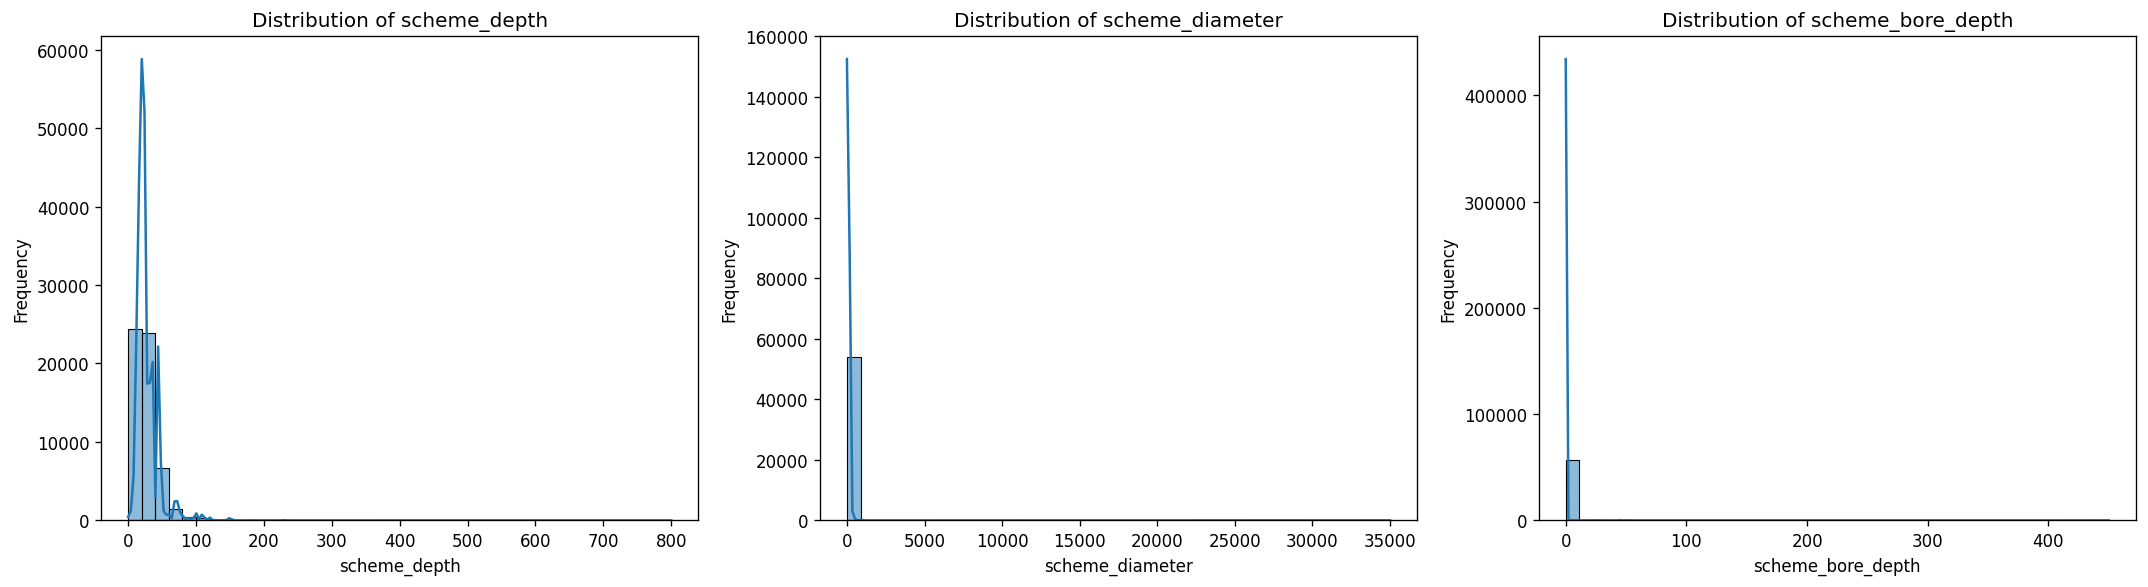

In [197]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, cols):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

In [198]:
for col in ['scheme_depth', 'scheme_diameter', 'scheme_bore_depth']:
    s = df[col]

    print(f"\n--- {col} ---")
    print("Zero values:", (s == 0).sum())
    print("Values below 1:", ((s > 0) & (s < 1)).sum())
    print("Values above 100:", (s > 100).sum())
    print("Values above 500:", (s > 500).sum())
    print("\nLargest 15 values:")
    print(s.nlargest(15).to_list())


--- scheme_depth ---
Zero values: 0
Values below 1: 28
Values above 100: 483
Values above 500: 1

Largest 15 values:
[800.0, 450.0, 400.0, 350.0, 350.0, 350.0, 310.0, 300.0, 300.0, 300.0, 300.0, 270.0, 230.0, 230.0, 230.0]

--- scheme_diameter ---
Zero values: 64
Values below 1: 12281
Values above 100: 10378
Values above 500: 82

Largest 15 values:
[35000.0, 35000.0, 35000.0, 28000.0, 28000.0, 28000.0, 26500.0, 25000.0, 19000.0, 15025.0, 11020.0, 10668.0, 10030.0, 10020.0, 10001.0]

--- scheme_bore_depth ---
Zero values: 57028
Values below 1: 25
Values above 100: 16
Values above 500: 0

Largest 15 values:
[450.0, 450.0, 450.0, 350.0, 250.0, 250.0, 200.0, 200.0, 200.0, 200.0, 150.0, 130.0, 120.0, 110.0, 110.0]


In [199]:
pd.crosstab(
    df['scheme_type'],
    df['scheme_bore_depth'].eq(0).map({
        True: 'Zero',
        False: 'Non-zero'
    })
)

scheme_bore_depth,Non-zero,Zero
scheme_type,,
Dug well,76,733
Tube well,199,56295


In [200]:
df.drop(columns=['scheme_bore_depth'], inplace=True) # too many 0 values

In [201]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_kharif_season,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33


In [202]:
df.groupby('scheme_type')['scheme_diameter'].agg(
    ['count', 'median', 'min', 'max']
)

,count,median,min,max
scheme_type,,,,
Dug well,792,1.0,0.0,1000.0
Tube well,53357,80.0,0.0,35000.0


In [203]:
df['scheme_diameter'] = df['scheme_diameter'].fillna(
    df.groupby('scheme_type')['scheme_diameter'].transform('median')
)

In [204]:
print("Remaining missing values:", df['scheme_diameter'].isnull().sum())

Remaining missing values: 0


In [205]:
print("Zero diameter values:", (df['scheme_diameter'] == 0).sum())

display(
    df.loc[df['scheme_diameter'] == 0, 'scheme_type']
      .value_counts(dropna=False)
      .to_frame('Zero_Count')
)

Zero diameter values: 64


,Zero_Count
scheme_type,
Tube well,56
Dug well,8


In [ ]:
import numpy as np

df['scheme_diameter'] = df['scheme_diameter'].replace(0, np.nan)

print("Missing values after replacing zeros:", df['scheme_diameter'].isnull().sum())

Missing values after replacing zeros: 64


In [ ]:
df['scheme_diameter'] = df['scheme_diameter'].fillna(
    df.groupby('scheme_type')['scheme_diameter'].transform('median')
)

In [ ]:
print("Remaining missing values:", df['scheme_diameter'].isnull().sum())
print("Remaining zero values:", (df['scheme_diameter'] == 0).sum())

Remaining missing values: 0
Remaining zero values: 0


In [ ]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_kharif_season,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_rabi_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
captured_in_previous_census,object,837,1.46


In [ ]:
pd.crosstab(
    df['scheme_status'],
    df['captured_in_previous_census'].isna(),
    margins=True
)

captured_in_previous_census,False,True,All
scheme_status,,,
In-Use,50413,781,51194
Permanently Not in use,755,12,767
Temporarily Not in use,5298,44,5342
All,56466,837,57303


In [ ]:
print(df['captured_in_previous_census'].value_counts(dropna=False))

captured_in_previous_census
No     55322
Yes     1144
NaN      837
Name: count, dtype: int64


In [ ]:
pd.crosstab(
    df['ownership'],
    df['captured_in_previous_census'],
    normalize='index'
).round(3) * 100

captured_in_previous_census,No,Yes
ownership,,
Co-Operative Owned,95.6,4.4
Govt. Owned,97.1,2.9
Others,99.3,0.7
Owned by Group of farmers,94.4,5.6
Owned by individual farmer,98.4,1.6
Panchayat Owned,97.6,2.4


In [ ]:
village_summary = df.groupby('village_name', dropna=False).agg(
    Total_Records=('captured_in_previous_census', 'size'),
    Missing_Capture=('captured_in_previous_census',
                     lambda x: x.isna().sum()),
    Unique_Capture_Values=('captured_in_previous_census', 'nunique')
)

village_summary['Missing_Percentage'] = (
    village_summary['Missing_Capture']
    / village_summary['Total_Records'] * 100
).round(2)

display(
    village_summary
    .sort_values(['Missing_Percentage', 'Total_Records'], ascending=False)
    .head(20)
)

,Total_Records,Missing_Capture,Unique_Capture_Values,Missing_Percentage
village_name,,,,
Bayasha,35,35,0,100.0
Bhogdia,28,28,0,100.0
Garartari,21,21,0,100.0
Rangia Gaon,17,17,0,100.0
Uttar Burikamar,17,17,0,100.0
Kaldi,16,16,0,100.0
Agdia,15,15,0,100.0
Khudra Bamunbari,15,15,0,100.0
Garia Chatala,11,11,0,100.0


In [ ]:
village_summary = df.groupby('village_name', dropna=False).agg(
    Total_Records=('captured_in_previous_census', 'size'),
    Missing_Capture=('captured_in_previous_census', lambda x: x.isna().sum())
)

village_summary['Missing_Percentage'] = (
    village_summary['Missing_Capture']
    / village_summary['Total_Records'] * 100
).round(2)

print("Total villages:", len(village_summary))
print("Villages with all values missing:",
      (village_summary['Missing_Percentage'] == 100).sum())
print("Villages with no missing values:",
      (village_summary['Missing_Percentage'] == 0).sum())
print("Villages with partially missing values:",
      ((village_summary['Missing_Percentage'] > 0) &
       (village_summary['Missing_Percentage'] < 100)).sum())

Total villages: 8393
Villages with all values missing: 57
Villages with no missing values: 8125
Villages with partially missing values: 211


In [ ]:
df['captured_in_previous_census'] = (
    df['captured_in_previous_census'].fillna('Unknown')
)

In [ ]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_rabi_season,float64,1907,3.33
pump_operating_days_kharif_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33
water_distribution_method,object,767,1.34


In [ ]:
print(df['water_distribution_method'].value_counts(dropna=False))

water_distribution_method
Surface pipe                             22690
Open Water Channel (unlined / Kutcha)    18596
Other                                    10832
Open Water Channel (lined / Pucca)        2241
Under ground pipe                         2057
NaN                                        767
Sprinkler                                   60
Drip                                        60
Name: count, dtype: int64


In [ ]:
pd.crosstab(
    df['scheme_status'],
    df['water_distribution_method'],
    margins=True,
    dropna=False
)

water_distribution_method,Drip,Open Water Channel (lined / Pucca),Open Water Channel (unlined / Kutcha),Other,Sprinkler,Surface pipe,Under ground pipe,NaN,All
scheme_status,,,,,,,,,
In-Use,53,1837,17118,9823,57,20515,1791,0,51194
Permanently Not in use,0,0,0,0,0,0,0,767,767
Temporarily Not in use,7,404,1478,1009,3,2175,266,0,5342
All,60,2241,18596,10832,60,22690,2057,0,57303


In [ ]:
df['water_distribution_method'] = (
    df['water_distribution_method'].fillna('Unknown')
)

In [ ]:
print(df['water_distribution_method'].isnull().sum())
print(df['water_distribution_method'].value_counts())

0
water_distribution_method
Surface pipe                             22690
Open Water Channel (unlined / Kutcha)    18596
Other                                    10832
Open Water Channel (lined / Pucca)        2241
Under ground pipe                         2057
Unknown                                    767
Sprinkler                                   60
Drip                                        60
Name: count, dtype: int64


In [ ]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_rabi_season,float64,1907,3.33
pump_operating_days_kharif_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33
energy_source,object,748,1.31


In [ ]:
cols = ['energy_source', 'lifting_device_type']

for col in cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- energy_source ---
energy_source
Diesel           27323
Electric         18689
Solar             8678
Manual/animal     1116
NaN                748
Others             702
Wind Mills          25
Natural             22
Name: count, dtype: int64

--- lifting_device_type ---
lifting_device_type
Centrifugal Pump    36890
Submersible pump    11950
Others               4793
Turbine/Jet pump     1806
Manual/animal        1116
NaN                   748
Name: count, dtype: int64


In [ ]:
for col in cols:
    print(f"\n--- {col} vs scheme_status ---")
    display(pd.crosstab(
        df['scheme_status'],
        df[col],
        margins=True,
        dropna=False
    ))


--- energy_source vs scheme_status ---


energy_source,Diesel,Electric,Manual/animal,Natural,Others,Solar,Wind Mills,NaN,All
scheme_status,,,,,,,,,
In-Use,25432,16246,1074,20,618,7780,24,0,51194
Permanently Not in use,8,8,1,1,0,1,0,748,767
Temporarily Not in use,1883,2435,41,1,84,897,1,0,5342
All,27323,18689,1116,22,702,8678,25,0,57303



--- lifting_device_type vs scheme_status ---


lifting_device_type,Centrifugal Pump,Manual/animal,Others,Submersible pump,Turbine/Jet pump,NaN,All
scheme_status,,,,,,,
In-Use,34603,1074,4451,9473,1593,0,51194
Permanently Not in use,9,1,1,8,0,748,767
Temporarily Not in use,2278,41,341,2469,213,0,5342
All,36890,1116,4793,11950,1806,0,57303


In [ ]:
cols = ['energy_source', 'lifting_device_type']

df[cols] = df[cols].fillna('Unknown')

In [ ]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
horse_power_of_lifting_device,float64,1919,3.35
pump_operating_days_kharif_season,float64,1907,3.33
pump_operating_days_rabi_season,float64,1907,3.33
pump_operating_days_perennial_crop,float64,1907,3.33
pump_operating_days_other_season,float64,1907,3.33
avg_pumping_per_day_kharif_season,float64,1907,3.33
avg_pumping_per_day_rabi_season,float64,1907,3.33
avg_pumping_per_day_perennial_crop,float64,1907,3.33
avg_pumping_per_day_other_season,float64,1908,3.33


In [ ]:
cols = [
    'pump_operating_days_kharif_season',
    'pump_operating_days_rabi_season',
    'pump_operating_days_perennial_crop',
    'pump_operating_days_other_season',
    'avg_pumping_per_day_kharif_season',
    'avg_pumping_per_day_rabi_season',
    'avg_pumping_per_day_perennial_crop',
    'avg_pumping_per_day_other_season'
]

# Missing-value counts and percentages
display(
    df[cols].isnull().sum().to_frame('Missing_Count')
    .assign(
        Missing_Percentage=lambda x:
        (x['Missing_Count'] / len(df) * 100).round(2)
    )
)

# Number of columns missing in each row
missing_per_row = df[cols].isnull().sum(axis=1)

print("\nRows by number of missing values in these columns:")
print(missing_per_row.value_counts().sort_index())

print("\nRows missing all 8 values:", (missing_per_row == 8).sum())
print("Rows with no missing values:", (missing_per_row == 0).sum())
print("Rows with partial missing values:",
      ((missing_per_row > 0) & (missing_per_row < 8)).sum())

,Missing_Count,Missing_Percentage
pump_operating_days_kharif_season,1907,3.33
pump_operating_days_rabi_season,1907,3.33
pump_operating_days_perennial_crop,1907,3.33
pump_operating_days_other_season,1907,3.33
avg_pumping_per_day_kharif_season,1907,3.33
avg_pumping_per_day_rabi_season,1907,3.33
avg_pumping_per_day_perennial_crop,1907,3.33
avg_pumping_per_day_other_season,1908,3.33



Rows by number of missing values in these columns:
0    55395
1        1
8     1907
Name: count, dtype: int64

Rows missing all 8 values: 1907
Rows with no missing values: 55395
Rows with partial missing values: 1


In [ ]:
display(df[cols].describe().T)

display(
    pd.DataFrame({
        'Zero_Count': (df[cols] == 0).sum(),
        'Missing_Count': df[cols].isnull().sum(),
        'Unique_Values': df[cols].nunique()
    })
)

,count,mean,std,min,25%,50%,75%,max
pump_operating_days_kharif_season,55396.0,37.226370,32.712928,0.0,10.0,30.0,60.0,650.0
pump_operating_days_rabi_season,55396.0,54.485667,34.008260,0.0,25.0,60.0,85.0,601.0
pump_operating_days_perennial_crop,55396.0,2.771030,12.708642,0.0,0.0,0.0,0.0,360.0
pump_operating_days_other_season,55396.0,7.032078,15.242564,0.0,0.0,0.0,8.0,365.0
avg_pumping_per_day_kharif_season,55396.0,4.266982,2.849938,0.0,3.0,4.0,6.0,120.0
avg_pumping_per_day_rabi_season,55396.0,5.481138,3.000532,0.0,4.0,6.0,7.0,150.0
avg_pumping_per_day_perennial_crop,55396.0,0.369825,1.376124,0.0,0.0,0.0,0.0,120.0
avg_pumping_per_day_other_season,55395.0,1.028560,1.978623,0.0,0.0,0.0,2.0,60.0


,Zero_Count,Missing_Count,Unique_Values
pump_operating_days_kharif_season,7480,1907,123
pump_operating_days_rabi_season,2488,1907,140
pump_operating_days_perennial_crop,49136,1907,72
pump_operating_days_other_season,39391,1907,82
avg_pumping_per_day_kharif_season,7477,1907,53
avg_pumping_per_day_rabi_season,2489,1907,64
avg_pumping_per_day_perennial_crop,49135,1907,29
avg_pumping_per_day_other_season,39404,1908,36


In [ ]:
cols = [
    'pump_operating_days_kharif_season',
    'pump_operating_days_rabi_season',
    'pump_operating_days_perennial_crop',
    'pump_operating_days_other_season',
    'avg_pumping_per_day_kharif_season',
    'avg_pumping_per_day_rabi_season',
    'avg_pumping_per_day_perennial_crop',
    'avg_pumping_per_day_other_season'
]

df['operational_data_missing'] = df[cols].isna().all(axis=1)

display(
    pd.crosstab(
        df['scheme_status'],
        df['operational_data_missing'],
        margins=True
    )
)

display(
    pd.crosstab(
        df['scheme_status'],
        df['operational_data_missing'],
        normalize='index'
    ).mul(100).round(2)
)

operational_data_missing,False,True,All
scheme_status,,,
In-Use,50100,1094,51194
Permanently Not in use,0,767,767
Temporarily Not in use,5296,46,5342
All,55396,1907,57303


operational_data_missing,False,True
scheme_status,,
In-Use,97.86,2.14
Permanently Not in use,0.00,100.00
Temporarily Not in use,99.14,0.86


In [233]:
cols = [
    'pump_operating_days_kharif_season',
    'pump_operating_days_rabi_season',
    'pump_operating_days_perennial_crop',
    'pump_operating_days_other_season',
    'avg_pumping_per_day_kharif_season',
    'avg_pumping_per_day_rabi_season',
    'avg_pumping_per_day_perennial_crop',
    'avg_pumping_per_day_other_season'
]

mask = df['scheme_status'].eq('Permanently Not in use')

df.loc[mask, cols] = df.loc[mask, cols].fillna(0)

In [235]:
cols = [
    'pump_operating_days_kharif_season',
    'pump_operating_days_rabi_season',
    'pump_operating_days_perennial_crop',
    'pump_operating_days_other_season',
    'avg_pumping_per_day_kharif_season',
    'avg_pumping_per_day_rabi_season',
    'avg_pumping_per_day_perennial_crop',
    'avg_pumping_per_day_other_season'
]

df['operational_data_missing'] = df[cols].isna().all(axis=1)

display(
    pd.crosstab(
        df['scheme_status'],
        df['operational_data_missing'],
        margins=True
    )
)

display(
    pd.crosstab(
        df['scheme_status'],
        df['operational_data_missing'],
        normalize='index'
    ).mul(100).round(2)
)

operational_data_missing,False,True,All
scheme_status,,,
In-Use,50100,1094,51194
Permanently Not in use,767,0,767
Temporarily Not in use,5296,46,5342
All,56163,1140,57303


operational_data_missing,False,True
scheme_status,,
In-Use,97.86,2.14
Permanently Not in use,100.00,0.00
Temporarily Not in use,99.14,0.86


In [236]:
cols = [
    'pump_operating_days_kharif_season',
    'pump_operating_days_rabi_season',
    'pump_operating_days_perennial_crop',
    'pump_operating_days_other_season',
    'avg_pumping_per_day_kharif_season',
    'avg_pumping_per_day_rabi_season',
    'avg_pumping_per_day_perennial_crop',
    'avg_pumping_per_day_other_season'
]

mask = df[cols].isna().any(axis=1)

display(
    df.loc[mask, ['scheme_status', 'ownership', 'scheme_type']]
      .value_counts(dropna=False)
      .head(20)
      .to_frame('Count')
)

Count
scheme_status          ownership                  scheme_type       
In-Use                 Owned by individual farmer Tube well      241
                       Owned by Group of farmers  Tube well      216
                       Owned by individual farmer Dug well       214
                       Others                     Dug well       150
                                                  Tube well       87
                       Govt. Owned                Tube well       77
                                                  Dug well        68
                       Panchayat Owned            Dug well        14
                       Owned by Group of farmers  Dug well        12
                       Panchayat Owned            Tube well       10
Temporarily Not in use Govt. Owned                Dug well         9
                       Owned by individual farmer Tube well        9
                       Govt. Owned                Tube well        8
                       Others                     Dug well         7
                       Owned by individual farmer Dug well         5
In-Use                 Co-Operative Owned         Tube well        3
                                                  Dug well         3
Temporarily Not in use Owned by Group of farmers  Dug well         3
                       Panchayat Owned            Dug well         2
                       Co-Operative Owned         Dug well         1

In [237]:
cols = [
    'pump_operating_days_kharif_season',
    'pump_operating_days_rabi_season',
    'pump_operating_days_perennial_crop',
    'pump_operating_days_other_season',
    'avg_pumping_per_day_kharif_season',
    'avg_pumping_per_day_rabi_season',
    'avg_pumping_per_day_perennial_crop',
    'avg_pumping_per_day_other_season'
]

group_cols = ['scheme_status', 'scheme_type']

for col in cols:
    group_median = df.groupby(group_cols, dropna=False)[col].transform('median')
    df[col] = df[col].fillna(group_median)

In [238]:
display(
    df[cols].isna().sum().to_frame('Remaining_Missing')
)

print("Rows with any missing operational value:",
      df[cols].isna().any(axis=1).sum())

,Remaining_Missing
pump_operating_days_kharif_season,0
pump_operating_days_rabi_season,0
pump_operating_days_perennial_crop,0
pump_operating_days_other_season,0
avg_pumping_per_day_kharif_season,0
avg_pumping_per_day_rabi_season,0
avg_pumping_per_day_perennial_crop,0
avg_pumping_per_day_other_season,0


Rows with any missing operational value: 0


In [239]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
horse_power_of_lifting_device,float64,1919,3.35


In [243]:
print(df['horse_power_of_lifting_device'].describe())

print("\nMost common horsepower values:")
print(df['horse_power_of_lifting_device'].value_counts(dropna=False).head(20))

count    55384.000000
mean         4.053828
std         13.785432
min          0.080000
25%          2.000000
50%          3.000000
75%          5.000000
max       1800.000000
Name: horse_power_of_lifting_device, dtype: float64

Most common horsepower values:
horse_power_of_lifting_device
5.0     24491
2.0     14848
3.0     10667
NaN      1919
1.5      1455
7.5       743
4.0       693
1.0       569
20.0      505
2.5       312
3.5       252
10.0      140
15.0      130
7.0       120
30.0       66
8.0        50
25.0       46
2.1        45
6.0        43
0.5        23
Name: count, dtype: int64


In [244]:
for col in ['lifting_device_type', 'energy_source', 'scheme_status']:
    print(f"\n--- {col} ---")
    display(
        df.groupby(col, dropna=False)['horse_power_of_lifting_device']
          .agg(
              Total='size',
              Missing='count'
          )
    )


--- lifting_device_type ---


,Total,Missing
lifting_device_type,,
Centrifugal Pump,36890,36877
Manual/animal,1116,0
Others,4793,4764
Submersible pump,11950,11937
Turbine/Jet pump,1806,1806
Unknown,748,0



--- energy_source ---


,Total,Missing
energy_source,,
Diesel,27323,27315
Electric,18689,18681
Manual/animal,1116,0
Natural,22,0
Others,702,686
Solar,8678,8677
Unknown,748,0
Wind Mills,25,25



--- scheme_status ---


,Total,Missing
scheme_status,,
In-Use,51194,50090
Permanently Not in use,767,0
Temporarily Not in use,5342,5294


In [245]:
for col in ['lifting_device_type', 'energy_source', 'scheme_status']:
    summary = df.groupby(col, dropna=False).agg(
        Total=('horse_power_of_lifting_device', 'size'),
        Non_Missing=('horse_power_of_lifting_device', 'count')
    )

    summary['Missing'] = summary['Total'] - summary['Non_Missing']
    summary['Missing_Percentage'] = (
        summary['Missing'] / summary['Total'] * 100
    ).round(2)

    print(f"\n--- {col} ---")
    display(summary)


--- lifting_device_type ---


,Total,Non_Missing,Missing,Missing_Percentage
lifting_device_type,,,,
Centrifugal Pump,36890,36877,13,0.04
Manual/animal,1116,0,1116,100.00
Others,4793,4764,29,0.61
Submersible pump,11950,11937,13,0.11
Turbine/Jet pump,1806,1806,0,0.00
Unknown,748,0,748,100.00



--- energy_source ---


,Total,Non_Missing,Missing,Missing_Percentage
energy_source,,,,
Diesel,27323,27315,8,0.03
Electric,18689,18681,8,0.04
Manual/animal,1116,0,1116,100.00
Natural,22,0,22,100.00
Others,702,686,16,2.28
Solar,8678,8677,1,0.01
Unknown,748,0,748,100.00
Wind Mills,25,25,0,0.00



--- scheme_status ---


,Total,Non_Missing,Missing,Missing_Percentage
scheme_status,,,,
In-Use,51194,50090,1104,2.16
Permanently Not in use,767,0,767,100.00
Temporarily Not in use,5342,5294,48,0.90


In [246]:
mask = (
    df['horse_power_of_lifting_device'].isna()
    & df['lifting_device_type'].ne('Manual/animal')
    & df['lifting_device_type'].ne('Unknown')
    & df['scheme_status'].ne('Permanently Not in use')
)

display(
    df.loc[
        mask,
        [
            'lifting_device_type',
            'energy_source',
            'scheme_status',
            'scheme_type',
            'horse_power_of_lifting_device'
        ]
    ].value_counts(dropna=False).to_frame('Count')
)

Count
lifting_device_type energy_source scheme_status          scheme_type horse_power_of_lifting_device       
Others              Natural       In-Use                 Tube well   NaN                               20
                    Others        Temporarily Not in use Tube well   NaN                                6
Submersible pump    Others        In-Use                 Tube well   NaN                                5
Centrifugal Pump    Others        In-Use                 Tube well   NaN                                4
Others              Others        In-Use                 Tube well   NaN                                1
                    Natural       Temporarily Not in use Tube well   NaN                                1

In [247]:
hp_col = 'horse_power_of_lifting_device'

mask = (
    df[hp_col].isna()
    & df['lifting_device_type'].ne('Manual/animal')
    & df['lifting_device_type'].ne('Unknown')
    & df['scheme_status'].ne('Permanently Not in use')
)

display(
    df.loc[mask, [
        'lifting_device_type',
        'energy_source',
        'scheme_type',
        'scheme_status',
        hp_col
    ]]
)

,lifting_device_type,energy_source,scheme_type,scheme_status,horse_power_of_lifting_device
2705,Centrifugal Pump,Others,Tube well,In-Use,NaN
16860,Others,Natural,Tube well,In-Use,NaN
27859,Others,Others,Tube well,Temporarily Not in use,NaN
27860,Others,Others,Tube well,Temporarily Not in use,NaN
28068,Others,Others,Tube well,Temporarily Not in use,NaN
28069,Others,Others,Tube well,Temporarily Not in use,NaN
28156,Others,Others,Tube well,Temporarily Not in use,NaN
28158,Centrifugal Pump,Others,Tube well,In-Use,NaN
28161,Submersible pump,Others,Tube well,In-Use,NaN
28163,Centrifugal Pump,Others,Tube well,In-Use,NaN


In [248]:
display(
    df.groupby(
        ['lifting_device_type', 'energy_source'],
        dropna=False
    )['horse_power_of_lifting_device']
    .agg(['count', 'median', 'mean', 'min', 'max'])
    .sort_values('count', ascending=False)
)

count  median      mean   min     max
lifting_device_type energy_source                                       
Centrifugal Pump    Diesel         22161     5.0  4.628126  0.50    60.0
                    Electric       11385     2.0  2.464895  0.25    40.0
Submersible pump    Electric        5486     3.0  5.017630  0.30   100.0
                    Solar           5050     3.0  4.134234  0.15   450.0
Centrifugal Pump    Solar           2980     2.0  4.302114  1.00  1800.0
Others              Diesel          2964     5.0  3.909750  1.00    30.0
Submersible pump    Diesel          1254     5.0  4.507337  0.15    56.0
Others              Electric        1199     2.0  2.687306  0.08    30.0
Turbine/Jet pump    Diesel           936     5.0  4.664017  0.15   106.0
                    Electric         611     3.0  4.156628  1.00   130.0
Others              Solar            433     2.5  3.041109  1.00    25.0
Centrifugal Pump    Others           339     5.0  4.650442  1.00    10.0
Turbine/Jet pump    Solar            214     5.0  4.782664  1.00    30.0
Others              Others           167     3.0  3.768263  1.00    25.0
Submersible pump    Others           136     3.0  3.485294  1.00    23.0
Turbine/Jet pump    Others            44     5.0  4.238636  1.00     5.0
Centrifugal Pump    Wind Mills        12     2.0  2.916667  1.50     5.0
Submersible pump    Wind Mills        11     3.5  4.545455  2.00     7.5
Turbine/Jet pump    Wind Mills         1     3.0  3.000000  3.00     3.0
Others              Wind Mills         1     3.0  3.000000  3.00     3.0
Manual/animal       Manual/animal      0     NaN       NaN   NaN     NaN
Others              Natural            0     NaN       NaN   NaN     NaN
Unknown             Unknown            0     NaN       NaN   NaN     NaN

In [249]:
import numpy as np

hp_col = 'horse_power_of_lifting_device'

# Fill specified combinations with zero
zero_mask = (
    (df['lifting_device_type'].eq('Manual/animal') &
     df['energy_source'].eq('Manual/animal'))
    | (df['lifting_device_type'].eq('Others') &
       df['energy_source'].eq('Natural'))
    | (df['lifting_device_type'].eq('Unknown') &
       df['energy_source'].eq('Unknown'))
)

df.loc[zero_mask & df[hp_col].isna(), hp_col] = 0

# Fill remaining missing values using group medians
group_median = df.groupby(
    ['lifting_device_type', 'energy_source'],
    dropna=False
)[hp_col].transform('median')

device_median = df.groupby(
    'lifting_device_type',
    dropna=False
)[hp_col].transform('median')

median_values = group_median.fillna(device_median)

remaining_missing = df[hp_col].isna()
df.loc[remaining_missing, hp_col] = median_values.loc[remaining_missing]

# Verify
print("Missing values remaining:", df[hp_col].isna().sum())

Missing values remaining: 0


In [250]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage


In [252]:
df.to_csv("Missing_treated.csv", index=False)